In [1]:
!pip install upsetplot -q
!pip install matplotlib-venn -q
!pip install gprofiler-official -q


# Standard library
import os
import re
from collections import defaultdict

# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams

# Specialized plots
from matplotlib_venn import venn2
from upsetplot import UpSet

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
COLORS = {
    "CTL": "#C8E6C9",
    "ETOH": "#FFC067",
    "SHARED": "#A0C4DF"
}

plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 16,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 18
})

FIG_DIR = "Figures"

os.makedirs(
    FIG_DIR,
    exist_ok=True
)


# FragPIPE analysis

In [3]:
file_path = "FragPIPE.csv"

df = pd.read_csv(file_path, sep=None, engine="python")

print("Dimensão original:", df.shape)

display(df.head())

rename_dict = {

    "OA_12jan26_Sami_Carol_imunopep_P004_CTL Intensity": "P004_CTL",
    "OA_12jan26_Sami_Carol_imunopep_P004_ETOH Intensity": "P004_ETOH",

    "OA_12jan26_Sami_Carol_imunopep_P114_CTL Intensity": "P114_CTL",
    "OA_12jan26_Sami_Carol_imunopep_P114_ETOH Intensity": "P114_ETOH",

    "OA_12jan26_Sami_Carol_imunopep_P118_CTL Intensity": "P118_CTL",
    "OA_12jan26_Sami_Carol_imunopep_P118_ETOH Intensity": "P118_ETOH"
}

df.rename(columns=rename_dict, inplace=True)

output_file = "FragPIPE_renamed.csv"

df.to_csv(output_file, index=False)

Dimensão original: (5274, 38)


,Peptide Sequence,Prev AA,Next AA,Start,End,Peptide Length,Charges,Protein,Protein ID,Entry Name,...,OA_12jan26_Sami_Carol_imunopep_P114_CTL MaxLFQ Intensity,OA_12jan26_Sami_Carol_imunopep_P114_ETOH MaxLFQ Intensity,OA_12jan26_Sami_Carol_imunopep_P118_CTL MaxLFQ Intensity,OA_12jan26_Sami_Carol_imunopep_P118_ETOH MaxLFQ Intensity,OA_12jan26_Sami_Carol_imunopep_P004_CTL Match Type,OA_12jan26_Sami_Carol_imunopep_P004_ETOH Match Type,OA_12jan26_Sami_Carol_imunopep_P114_CTL Match Type,OA_12jan26_Sami_Carol_imunopep_P114_ETOH Match Type,OA_12jan26_Sami_Carol_imunopep_P118_CTL Match Type,OA_12jan26_Sami_Carol_imunopep_P118_ETOH Match Type
0,AAAAAAAQSVY,L,A,7,17,11,2,sp|P07203|GPX1_HUMAN,P07203,GPX1_HUMAN,...,0.0,0.0,302907.100,520008.840,unmatched,unmatched,unmatched,unmatched,MS/MS,MS/MS
1,AAAAAAQSVY,A,A,8,17,10,2,sp|P07203|GPX1_HUMAN,P07203,GPX1_HUMAN,...,0.0,0.0,205608.250,658477.800,unmatched,unmatched,unmatched,unmatched,MS/MS,MBR
2,AAAAAHTFF,L,V,173,181,9,2,sp|Q8IVL6|P3H3_HUMAN,Q8IVL6,P3H3_HUMAN,...,0.0,0.0,0.000,0.000,unmatched,unmatched,unmatched,unmatched,unmatched,MS/MS
3,AAAAAQSVY,A,A,9,17,9,2,sp|P07203|GPX1_HUMAN,P07203,GPX1_HUMAN,...,0.0,0.0,110102.590,268285.900,unmatched,unmatched,unmatched,unmatched,MBR,MS/MS
4,AAAASPAILPR,M,L,2,12,11,2,sp|Q9BZM4|ULBP3_HUMAN,Q9BZM4,ULBP3_HUMAN,...,0.0,0.0,58528.477,56194.188,unmatched,unmatched,unmatched,unmatched,MS/MS,MS/MS


In [4]:
file_path = "FragPIPE_renamed.csv"

df = pd.read_csv(file_path)

ctl_cols = [
    "P004_CTL",
    "P114_CTL",
    "P118_CTL"
]

etoh_cols = [
    "P004_ETOH",
    "P114_ETOH",
    "P118_ETOH"
]

all_cols = ctl_cols + etoh_cols

df[all_cols] = (
    df[all_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

presence = pd.DataFrame()

presence["Peptide Sequence"] = (
    df["Peptide Sequence"]
    .astype(str)
    .str.strip()
)

for col in all_cols:
    presence[col] = df[col] > 0

presence = presence.drop_duplicates()

presence["CTL_count"] = (
    presence[ctl_cols]
    .sum(axis=1)
)

presence["ETOH_count"] = (
    presence[etoh_cols]
    .sum(axis=1)
)

exclusive_ctl = presence[
    (presence["CTL_count"] > 0) &
    (presence["ETOH_count"] == 0)
]

exclusive_etoh = presence[
    (presence["ETOH_count"] > 0) &
    (presence["CTL_count"] == 0)
]

shared = presence[
    (presence["CTL_count"] > 0) &
    (presence["ETOH_count"] > 0)
]


ctl_peptides = sorted(
    exclusive_ctl["Peptide Sequence"]
    .dropna()
    .unique()
)

etoh_peptides = sorted(
    exclusive_etoh["Peptide Sequence"]
    .dropna()
    .unique()
)

shared_peptides = sorted(
    shared["Peptide Sequence"]
    .dropna()
    .unique()
)

print(f"CTL only: {len(ctl_peptides)}")
print(f"ETOH only: {len(etoh_peptides)}")
print(f"Shared: {len(shared_peptides)}")

with open("ALL_CTL_only.txt", "w") as f:
    for pep in ctl_peptides:
        f.write(f"{pep}\n")

with open("ALL_ETOH_only.txt", "w") as f:
    for pep in etoh_peptides:
        f.write(f"{pep}\n")

with open("ALL_SHARED.txt", "w") as f:
    for pep in shared_peptides:
        f.write(f"{pep}\n")

print("Arquivos GibbsCluster gerados.")

CTL only: 1142
ETOH only: 663
Shared: 3413
Arquivos GibbsCluster gerados.


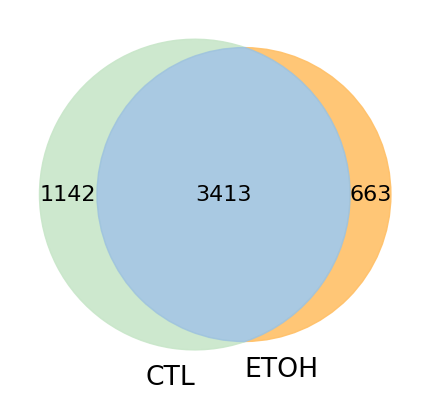

In [5]:
venn = venn2(
    subsets=(
        len(ctl_peptides),
        len(etoh_peptides),
        len(shared_peptides)
    ),
    set_labels=("CTL", "ETOH")
)

venn.get_patch_by_id('10').set_color(
    COLORS["CTL"]
)

venn.get_patch_by_id('01').set_color(
    COLORS["ETOH"]
)

venn.get_patch_by_id('11').set_color(
    COLORS["SHARED"]
)

venn.get_patch_by_id('10').set_alpha(0.9)
venn.get_patch_by_id('01').set_alpha(0.9)
venn.get_patch_by_id('11').set_alpha(0.9)

/usr/local/lib/python3.13/dist-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/usr/local/lib/python3.13/dist-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

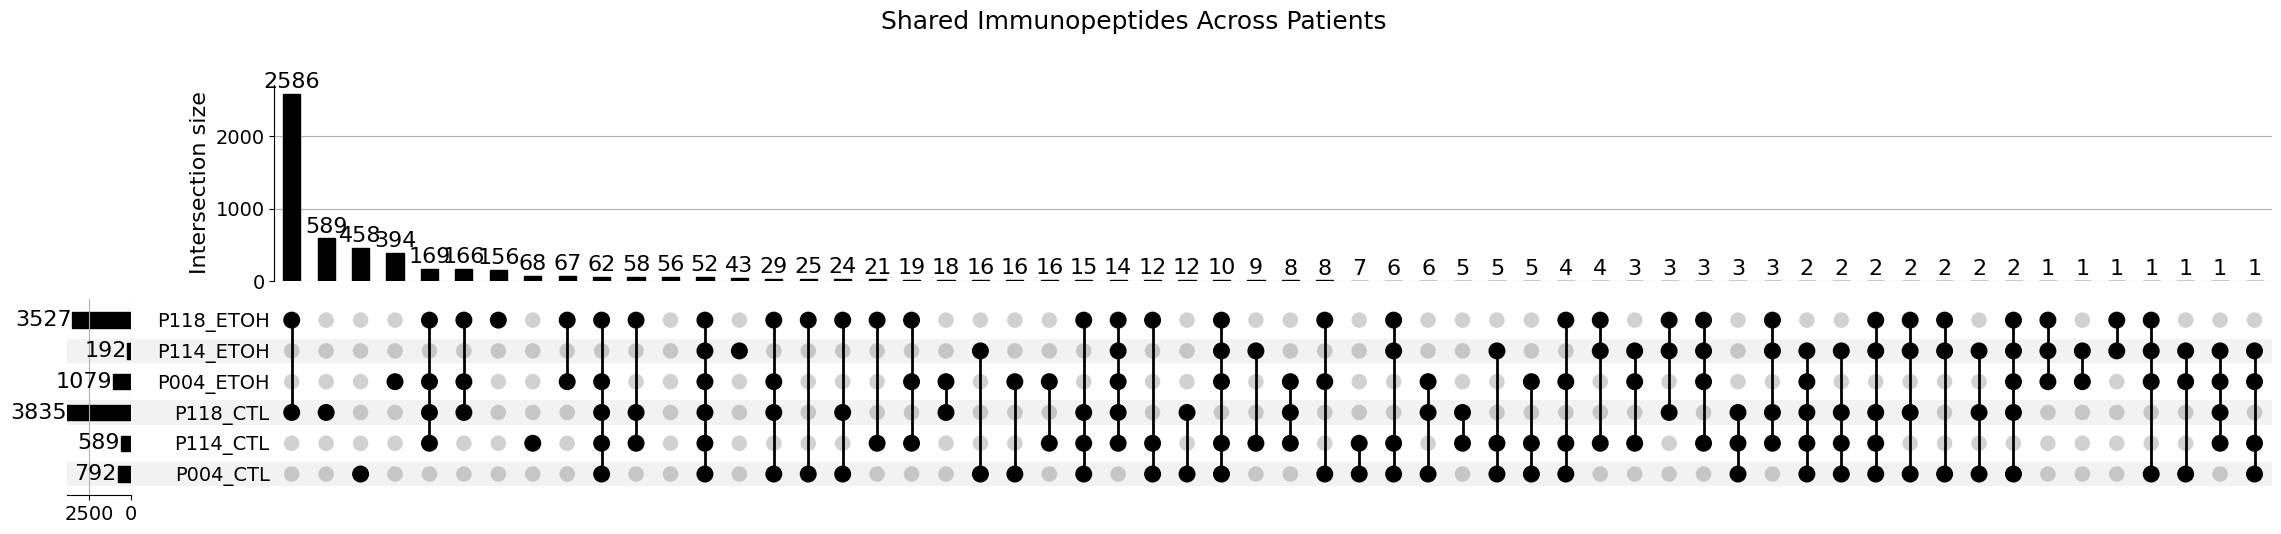

In [6]:
file_path = "FragPIPE_renamed.csv"

df = pd.read_csv(file_path)

conditions = [
    "P004_CTL",
    "P114_CTL",
    "P118_CTL",
    "P004_ETOH",
    "P114_ETOH",
    "P118_ETOH"
]

df[conditions] = (
    df[conditions]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

presence = pd.DataFrame()

presence["Peptide Sequence"] = (
    df["Peptide Sequence"]
    .astype(str)
    .str.strip()
)

for cond in conditions:
    presence[cond] = df[cond] > 0

presence = presence.drop_duplicates()

upset_data = (
    presence
    .set_index(conditions)
    .groupby(level=list(range(len(conditions))))
    .size()
)

plt.rcParams["figure.figsize"] = (14,7)

upset = UpSet(
    upset_data,
    show_counts=True,
    sort_by="cardinality",
    sort_categories_by=None
)

upset.plot()

plt.suptitle(
    "Shared Immunopeptides Across Patients",
    fontsize=18,
    y=1.02
)

plt.savefig(
    f"{FIG_DIR}/Figure_upset_global_fragpipe.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

CTL_ONLY: SB=165 | WB=136 | NON=171 | Total=472
ETOH_ONLY: SB=200 | WB=127 | NON=124 | Total=451
SHARED: SB=1126 | WB=662 | NON=723 | Total=2511


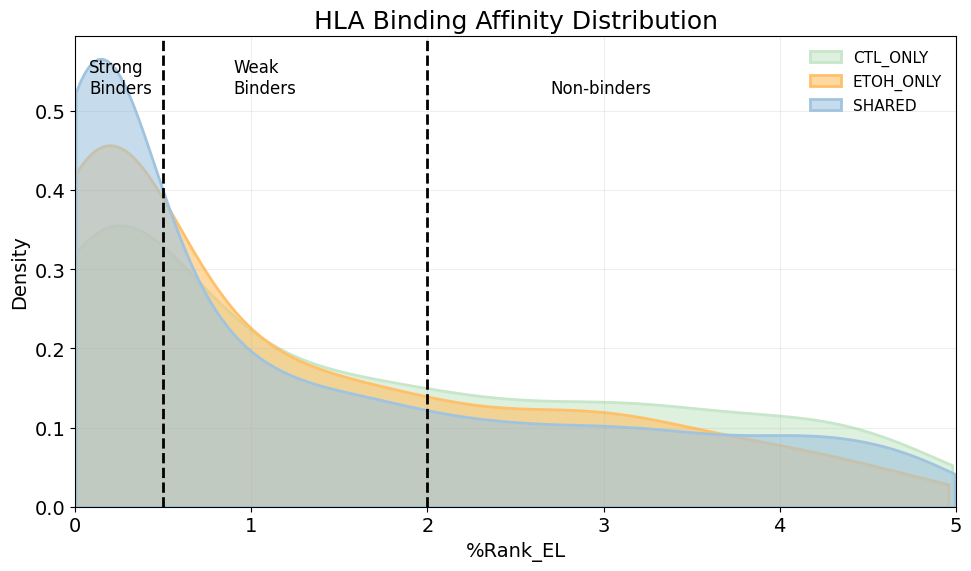

In [7]:
files = {
    "CTL_ONLY": "ctlonly_fragpipe.xlsx",
    "ETOH_ONLY": "etohonly_fragpipe.xlsx",
    "SHARED": "sharedonly_fragpipe.xlsx"
}

colors = {
    "CTL_ONLY": "#C8E6C9",
    "ETOH_ONLY": "#FFC067",
    "SHARED": "#A0C4DF"
}

data = {
    condition: pd.read_excel(filename)
    for condition, filename in files.items()
}

plt.figure(figsize=(10, 6))

for label, df in data.items():

    rank_col = next(
        col for col in df.columns
        if str(col).startswith("%Rank_EL")
    )

    ranks = pd.to_numeric(
        df[rank_col], errors="coerce"
    ).dropna()

    ranks = ranks[ranks.between(0, 5)]

    strong = (ranks <= 0.5).sum()

    weak = (
        (ranks > 0.5) &
        (ranks <= 2)
    ).sum()

    non = (ranks > 2).sum()

    print(
        f"{label}: "
        f"SB={strong} | "
        f"WB={weak} | "
        f"NON={non} | "
        f"Total={len(ranks)}"
    )

    sns.kdeplot(
        x=ranks,
        fill=True,
        common_norm=False,
        alpha=0.6,
        linewidth=2,
        label=label,
        color=colors[label],
        cut=0
    )

plt.axvline(
    0.5, linestyle="--",
    linewidth=2, color="black"
)

plt.axvline(
    2, linestyle="--",
    linewidth=2, color="black"
)

ymax = plt.ylim()[1]

plt.text(0.08, ymax * 0.88, "Strong\nBinders", fontsize=12)
plt.text(0.9, ymax * 0.88, "Weak\nBinders", fontsize=12)
plt.text(2.7, ymax * 0.88, "Non-binders", fontsize=12)

plt.xlabel("%Rank_EL", fontsize=14)
plt.ylabel("Density", fontsize=14)

plt.title(
    "HLA Binding Affinity Distribution",
    fontsize=18
)

plt.legend(frameon=False, fontsize=11)
plt.xlim(0, 5)
plt.grid(alpha=0.2)
plt.tight_layout()

os.makedirs(FIG_DIR, exist_ok=True)

plt.savefig(
    f"{FIG_DIR}/Figure_bindingaffinity_fragpipe.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
presence["CTL_count"] = presence[
    ["P004_CTL","P114_CTL","P118_CTL"]
].sum(axis=1)

presence["ETOH_count"] = presence[
    ["P004_ETOH","P114_ETOH","P118_ETOH"]
].sum(axis=1)

exclusive_ctl = presence[
    (presence["CTL_count"] >= 2) &
    (presence["ETOH_count"] == 0)
]

exclusive_etoh = presence[
    (presence["ETOH_count"] >= 2) &
    (presence["CTL_count"] == 0)
]

shared = presence[
    (presence["CTL_count"] > 0) &
    (presence["ETOH_count"] > 0)
]

In [9]:
shared = presence[
    (presence["CTL_count"] >= 2) &
    (presence["ETOH_count"] >= 2)
]

In [10]:
ctl_peptides = sorted(
    exclusive_ctl["Peptide Sequence"]
    .dropna()
    .unique()
)

etoh_peptides = sorted(
    exclusive_etoh["Peptide Sequence"]
    .dropna()
    .unique()
)

shared_peptides = sorted(
    shared["Peptide Sequence"]
    .dropna()
    .unique()
)

In [11]:
print(f"CTL only (≥2 pacientes): {len(ctl_peptides)}")
print(f"ETOH only (≥2 pacientes): {len(etoh_peptides)}")
print(f"Shared: {len(shared_peptides)}")

CTL only (≥2 pacientes): 27
ETOH only (≥2 pacientes): 70
Shared: 359


In [12]:
output_file = "Exclusive_Peptides_CTL_ETOH.xlsx"

with pd.ExcelWriter(output_file) as writer:

    exclusive_ctl[
        ["Peptide Sequence"]
    ].drop_duplicates().to_excel(
        writer,
        sheet_name="CTL_only",
        index=False
    )

    exclusive_etoh[
        ["Peptide Sequence"]
    ].drop_duplicates().to_excel(
        writer,
        sheet_name="ETOH_only",
        index=False
    )

    shared[
        ["Peptide Sequence"]
    ].drop_duplicates().to_excel(
        writer,
        sheet_name="Shared",
        index=False
    )

print(f"Arquivo salvo: {output_file}")

Arquivo salvo: Exclusive_Peptides_CTL_ETOH.xlsx


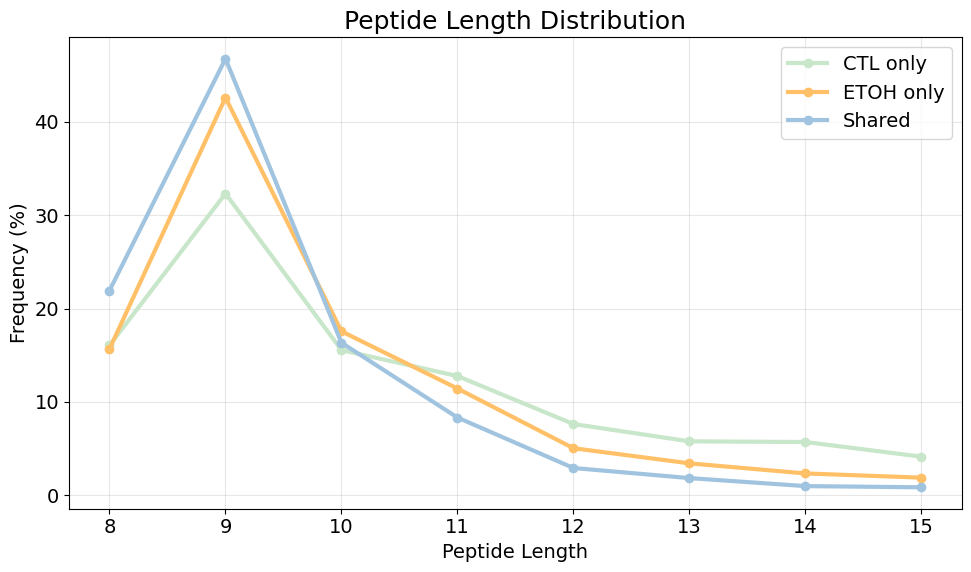

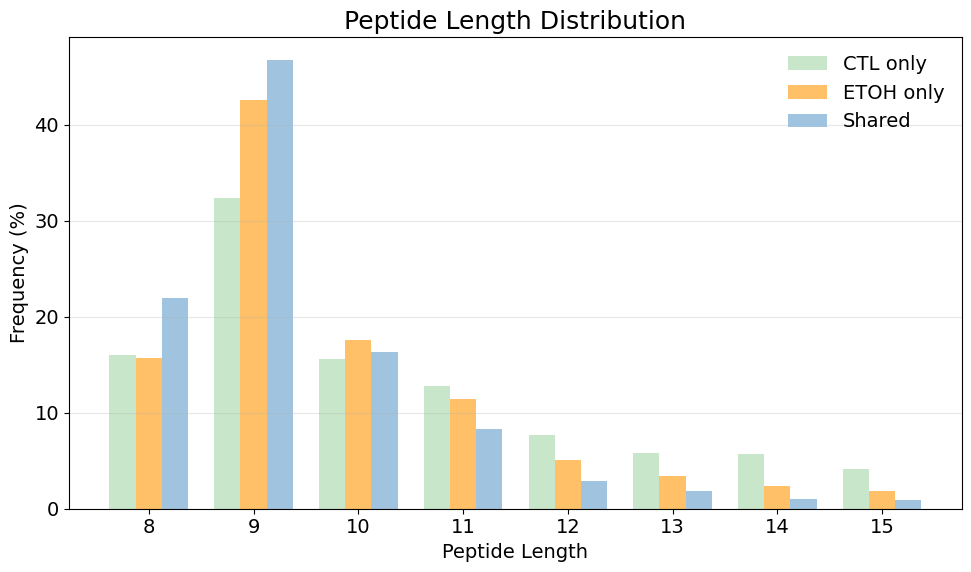

In [13]:
file_path = "FragPIPE_renamed.csv"

df = pd.read_csv(file_path)

patients = {
    "P004": ("P004_CTL", "P004_ETOH"),
    "P114": ("P114_CTL", "P114_ETOH"),
    "P118": ("P118_CTL", "P118_ETOH")
}

all_cols = [
    "P004_CTL", "P004_ETOH",
    "P114_CTL", "P114_ETOH",
    "P118_CTL", "P118_ETOH"
]

df[all_cols] = df[all_cols].apply(
    pd.to_numeric,
    errors="coerce"
).fillna(0)

all_ctl_only = set()
all_etoh_only = set()
all_shared = set()

for patient, (ctl, etoh) in patients.items():

    ctl_peptides = set(
        df.loc[
            df[ctl] > 0,
            "Peptide Sequence"
        ].dropna().astype(str).unique()
    )

    etoh_peptides = set(
        df.loc[
            df[etoh] > 0,
            "Peptide Sequence"
        ].dropna().astype(str).unique()
    )

    all_ctl_only.update(ctl_peptides - etoh_peptides)
    all_etoh_only.update(etoh_peptides - ctl_peptides)
    all_shared.update(ctl_peptides & etoh_peptides)


ctl_lengths = pd.Series([
    len(p) for p in all_ctl_only
])

etoh_lengths = pd.Series([
    len(p) for p in all_etoh_only
])

shared_lengths = pd.Series([
    len(p) for p in all_shared
])

ctl_lengths = ctl_lengths[
    ctl_lengths.between(8,15)
]

etoh_lengths = etoh_lengths[
    etoh_lengths.between(8,15)
]

shared_lengths = shared_lengths[
    shared_lengths.between(8,15)
]


ctl_freq = (
    ctl_lengths
    .value_counts()
    .sort_index()
)

etoh_freq = (
    etoh_lengths
    .value_counts()
    .sort_index()
)

shared_freq = (
    shared_lengths
    .value_counts()
    .sort_index()
)

ctl_freq = ctl_freq / ctl_freq.sum() * 100
etoh_freq = etoh_freq / etoh_freq.sum() * 100
shared_freq = shared_freq / shared_freq.sum() * 100


plt.figure(figsize=(10,6))

plt.plot(
    ctl_freq.index,
    ctl_freq.values,
    marker='o',
    linewidth=3,
    color=COLORS['CTL'],
    label='CTL only'
)

plt.plot(
    etoh_freq.index,
    etoh_freq.values,
    marker='o',
    linewidth=3,
    color=COLORS['ETOH'],
    label='ETOH only'
)

plt.plot(
    shared_freq.index,
    shared_freq.values,
    marker='o',
    linewidth=3,
    color=COLORS['SHARED'],
    label='Shared'
)

plt.xlabel(
    "Peptide Length",
    fontsize=14
)

plt.ylabel(
    "Frequency (%)",
    fontsize=14
)

plt.title(
    "Peptide Length Distribution",
    fontsize=18
)

plt.xticks(range(8,16))

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{FIG_DIR}/Figure_lengthdistribution_all_fragpipe.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

freq_df = pd.DataFrame({
    "CTL only": ctl_freq,
    "ETOH only": etoh_freq,
    "Shared": shared_freq
}).fillna(0)

x = np.arange(len(freq_df.index))
width = 0.25

plt.figure(figsize=(10,6))

plt.bar(
    x - width,
    freq_df["CTL only"],
    width=width,
    color=COLORS["CTL"],
    label="CTL only"
)

plt.bar(
    x,
    freq_df["ETOH only"],
    width=width,
    color=COLORS["ETOH"],
    label="ETOH only"
)

plt.bar(
    x + width,
    freq_df["Shared"],
    width=width,
    color=COLORS["SHARED"],
    label="Shared"
)

plt.xlabel("Peptide Length", fontsize=14)
plt.ylabel("Frequency (%)", fontsize=14)
plt.title("Peptide Length Distribution", fontsize=18)

plt.xticks(x, freq_df.index)

plt.legend()
plt.legend(frameon=False)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{FIG_DIR}/Figure_lengthdistribution_all_fragpipe_barplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
fragpipe = pd.read_csv("FragPIPE_renamed.csv")

print(fragpipe.columns.tolist())
fragpipe.head()

['Peptide Sequence', 'Prev AA', 'Next AA', 'Start', 'End', 'Peptide Length', 'Charges', 'Protein', 'Protein ID', 'Entry Name', 'Gene', 'Protein Description', 'Mapped Genes', 'Mapped Proteins', 'OA_12jan26_Sami_Carol_imunopep_P004_CTL Spectral Count', 'OA_12jan26_Sami_Carol_imunopep_P004_ETOH Spectral Count', 'OA_12jan26_Sami_Carol_imunopep_P114_CTL Spectral Count', 'OA_12jan26_Sami_Carol_imunopep_P114_ETOH Spectral Count', 'OA_12jan26_Sami_Carol_imunopep_P118_CTL Spectral Count', 'OA_12jan26_Sami_Carol_imunopep_P118_ETOH Spectral Count', 'P004_CTL', 'P004_ETOH', 'P114_CTL', 'P114_ETOH', 'P118_CTL', 'P118_ETOH', 'OA_12jan26_Sami_Carol_imunopep_P004_CTL MaxLFQ Intensity', 'OA_12jan26_Sami_Carol_imunopep_P004_ETOH MaxLFQ Intensity', 'OA_12jan26_Sami_Carol_imunopep_P114_CTL MaxLFQ Intensity', 'OA_12jan26_Sami_Carol_imunopep_P114_ETOH MaxLFQ Intensity', 'OA_12jan26_Sami_Carol_imunopep_P118_CTL MaxLFQ Intensity', 'OA_12jan26_Sami_Carol_imunopep_P118_ETOH MaxLFQ Intensity', 'OA_12jan26_Sami_C

,Peptide Sequence,Prev AA,Next AA,Start,End,Peptide Length,Charges,Protein,Protein ID,Entry Name,...,OA_12jan26_Sami_Carol_imunopep_P114_CTL MaxLFQ Intensity,OA_12jan26_Sami_Carol_imunopep_P114_ETOH MaxLFQ Intensity,OA_12jan26_Sami_Carol_imunopep_P118_CTL MaxLFQ Intensity,OA_12jan26_Sami_Carol_imunopep_P118_ETOH MaxLFQ Intensity,OA_12jan26_Sami_Carol_imunopep_P004_CTL Match Type,OA_12jan26_Sami_Carol_imunopep_P004_ETOH Match Type,OA_12jan26_Sami_Carol_imunopep_P114_CTL Match Type,OA_12jan26_Sami_Carol_imunopep_P114_ETOH Match Type,OA_12jan26_Sami_Carol_imunopep_P118_CTL Match Type,OA_12jan26_Sami_Carol_imunopep_P118_ETOH Match Type
0,AAAAAAAQSVY,L,A,7,17,11,2,sp|P07203|GPX1_HUMAN,P07203,GPX1_HUMAN,...,0.0,0.0,302907.100,520008.840,unmatched,unmatched,unmatched,unmatched,MS/MS,MS/MS
1,AAAAAAQSVY,A,A,8,17,10,2,sp|P07203|GPX1_HUMAN,P07203,GPX1_HUMAN,...,0.0,0.0,205608.250,658477.800,unmatched,unmatched,unmatched,unmatched,MS/MS,MBR
2,AAAAAHTFF,L,V,173,181,9,2,sp|Q8IVL6|P3H3_HUMAN,Q8IVL6,P3H3_HUMAN,...,0.0,0.0,0.000,0.000,unmatched,unmatched,unmatched,unmatched,unmatched,MS/MS
3,AAAAAQSVY,A,A,9,17,9,2,sp|P07203|GPX1_HUMAN,P07203,GPX1_HUMAN,...,0.0,0.0,110102.590,268285.900,unmatched,unmatched,unmatched,unmatched,MBR,MS/MS
4,AAAASPAILPR,M,L,2,12,11,2,sp|Q9BZM4|ULBP3_HUMAN,Q9BZM4,ULBP3_HUMAN,...,0.0,0.0,58528.477,56194.188,unmatched,unmatched,unmatched,unmatched,MS/MS,MS/MS


In [15]:
peptides = pd.read_excel("pep_frag_hla.xlsx")

In [16]:
ctl_peptides = (
    set(peptides["CTL_SB"].dropna()) |
    set(peptides["CTL_WB"].dropna())
)

etoh_peptides = (
    set(peptides["ETOH_SB"].dropna()) |
    set(peptides["ETOH_WB"].dropna())
)

shared_peptides = (
    set(peptides["Shared_SB"].dropna()) |
    set(peptides["Shared_WB"].dropna())
)

# Exclusivos
ctl_only = ctl_peptides - etoh_peptides - shared_peptides

etoh_only = etoh_peptides - ctl_peptides - shared_peptides

shared_only = shared_peptides - ctl_peptides - etoh_peptides

print("CTL only:", len(ctl_only))
print("ETOH only:", len(etoh_only))
print("Shared only:", len(shared_only))

CTL only: 148
ETOH only: 148
Shared only: 857


In [17]:
ctl_proteins = (
    fragpipe[
        fragpipe["Peptide Sequence"]
        .isin(ctl_only)
    ]["Protein ID"]
    .dropna()
    .astype(str)
    .unique()
)

etoh_proteins = (
    fragpipe[
        fragpipe["Peptide Sequence"]
        .isin(etoh_only)
    ]["Protein ID"]
    .dropna()
    .astype(str)
    .unique()
)

shared_proteins = (
    fragpipe[
        fragpipe["Peptide Sequence"]
        .isin(shared_only)
    ]["Protein ID"]
    .dropna()
    .astype(str)
    .unique()
)

print("CTL proteins:", len(ctl_proteins))
print("ETOH proteins:", len(etoh_proteins))
print("Shared proteins:", len(shared_proteins))

CTL proteins: 135
ETOH proteins: 142
Shared proteins: 738


In [18]:
from gprofiler import GProfiler

gp = GProfiler(return_dataframe=True)

res_ctl = gp.profile(
    organism="hsapiens",
    query=list(ctl_proteins),
    sources=["GO:BP"]
)

res_etoh = gp.profile(
    organism="hsapiens",
    query=list(etoh_proteins),
    sources=["GO:BP"]
)

res_shared = gp.profile(
    organism="hsapiens",
    query=list(shared_proteins),
    sources=["GO:BP"]
)

res_ctl = res_ctl.query("p_value < 0.05")
res_etoh = res_etoh.query("p_value < 0.05")
res_shared = res_shared.query("p_value < 0.05")

Quantificações de MS1

Peptídeos SB+WB: 1153
Peptídeos após filtro: 1153
Peptídeos presentes em ≥2 pacientes: 71


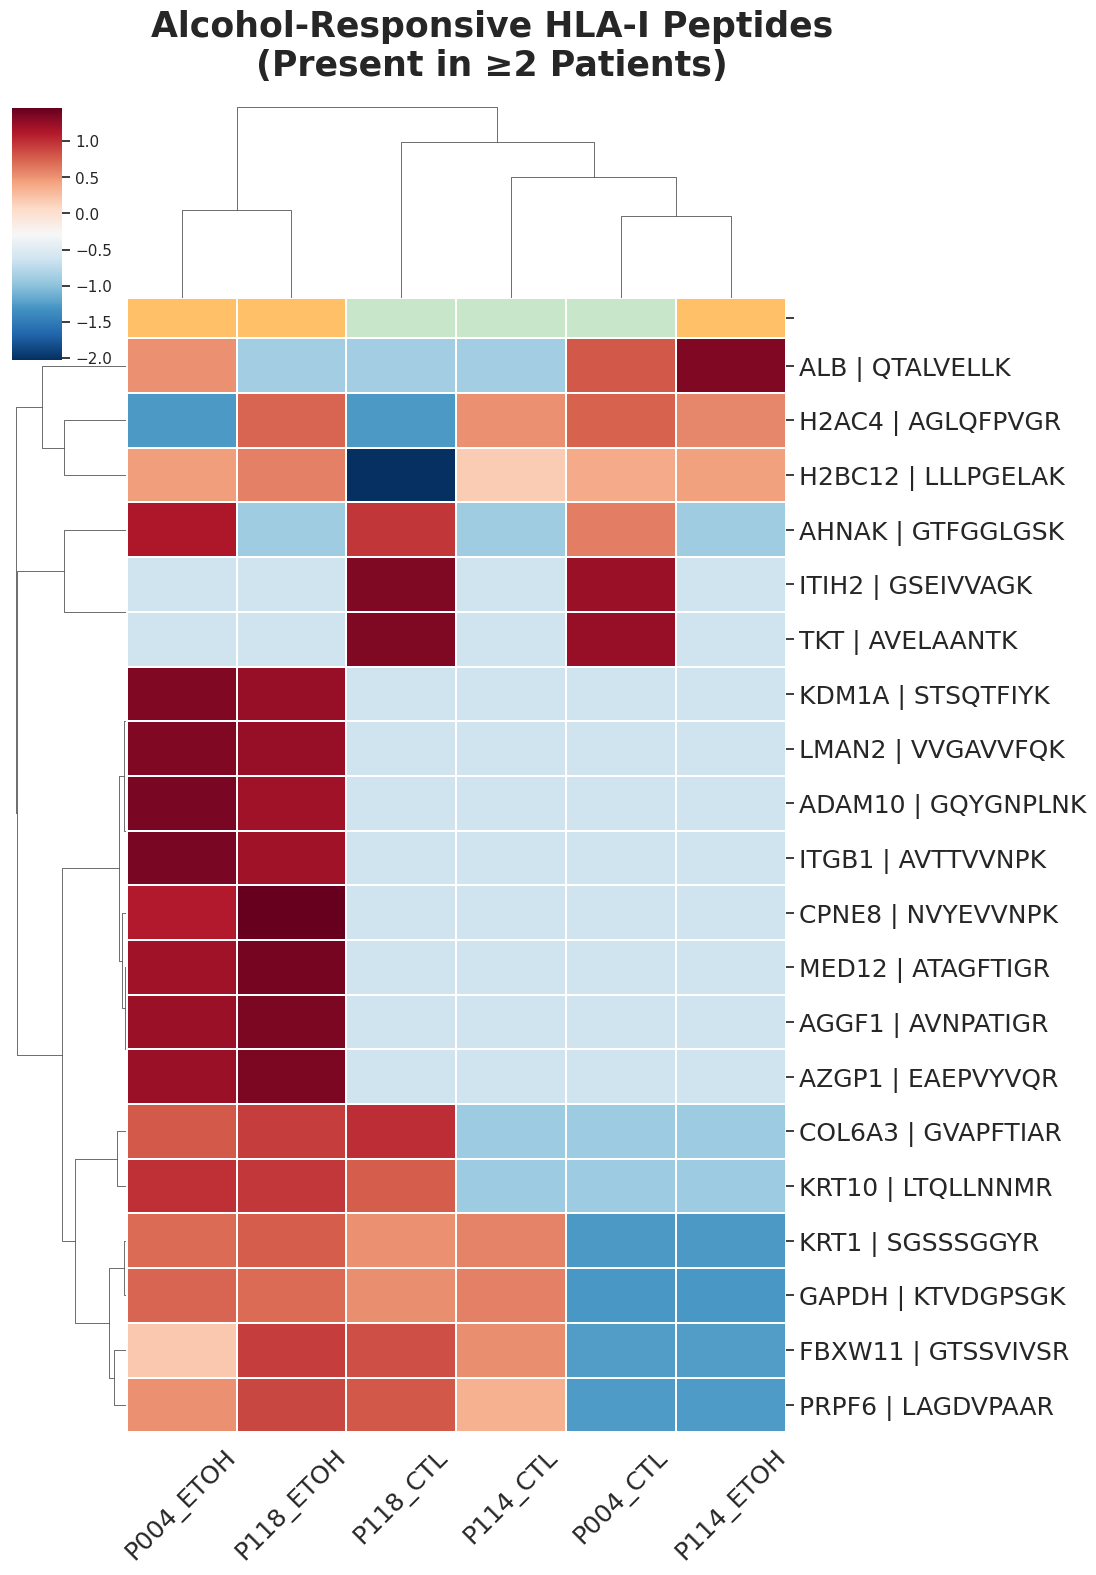

In [19]:
fragpipe = pd.read_csv("FragPIPE_renamed.csv")

hla = pd.read_excel("pep_frag_hla.xlsx")

selected_peptides = set()

for col in hla.columns:

    selected_peptides.update(
        hla[col]
        .dropna()
        .astype(str)
    )

print(
    "Peptídeos SB+WB:",
    len(selected_peptides)
)


df = fragpipe[
    fragpipe["Peptide Sequence"]
    .isin(selected_peptides)
].copy()

samples = [
    "P004_CTL",
    "P114_CTL",
    "P118_CTL",
    "P004_ETOH",
    "P114_ETOH",
    "P118_ETOH"
]

df[samples] = (
    df[samples]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)


matrix = (
    df
    .groupby("Peptide Sequence")[samples]
    .max()
)

matrix = np.log2(matrix + 1)

print(
    "Peptídeos após filtro:",
    matrix.shape[0]
)

ctl_presence = pd.DataFrame({
    "P004": matrix["P004_CTL"] > 0,
    "P114": matrix["P114_CTL"] > 0,
    "P118": matrix["P118_CTL"] > 0
})

etoh_presence = pd.DataFrame({
    "P004": matrix["P004_ETOH"] > 0,
    "P114": matrix["P114_ETOH"] > 0,
    "P118": matrix["P118_ETOH"] > 0
})

present_in_2_patients = (
    (ctl_presence.sum(axis=1) >= 2)
    |
    (etoh_presence.sum(axis=1) >= 2)
)

matrix = matrix[
    present_in_2_patients
].copy()

print(
    "Peptídeos presentes em ≥2 pacientes:",
    matrix.shape[0]
)

fc_matrix = pd.DataFrame({

    "P004":
        matrix["P004_ETOH"]
        -
        matrix["P004_CTL"],

    "P114":
        matrix["P114_ETOH"]
        -
        matrix["P114_CTL"],

    "P118":
        matrix["P118_ETOH"]
        -
        matrix["P118_CTL"]

})


score = (
    fc_matrix.abs()
    .mean(axis=1)
)

top_peptides = (
    score
    .sort_values(
        ascending=False
    )
    .head(20)
    .index
)

heatmap_data = (
    matrix
    .loc[top_peptides]
    .copy()
)

heatmap_data = heatmap_data[
    [
        "P004_CTL",
        "P004_ETOH",
        "P114_CTL",
        "P114_ETOH",
        "P118_CTL",
        "P118_ETOH"
    ]
]


pep2gene = (
    df[
        [
            "Peptide Sequence",
            "Gene"
        ]
    ]
    .dropna()
    .drop_duplicates()
    .groupby(
        "Peptide Sequence"
    )["Gene"]
    .first()
    .to_dict()
)


heatmap_data.index = [

    f"{pep2gene.get(pep,'NA')} | {pep}"

    for pep in heatmap_data.index

]


heatmap_data = heatmap_data.sub(
    heatmap_data.mean(axis=1),
    axis=0
)

heatmap_data = heatmap_data.div(
    heatmap_data.std(axis=1)
    .replace(0,1),
    axis=0
)


col_colors = pd.Series(

    [
        "#C8E6C9",
        "#FFC067",
         "#C8E6C9",
        "#FFC067",
         "#C8E6C9",
        "#FFC067"
    ],

    index=heatmap_data.columns

)

sns.set(
    style="white"
)

g = sns.clustermap(

    heatmap_data,

    cmap="RdBu_r",

    figsize=(10,14),

    row_cluster=True,
    col_cluster=True,

    col_colors=col_colors,

    linewidths=0.2,

    xticklabels=True,
    yticklabels=True,

    dendrogram_ratio=(0.15,0.15)

)


g.ax_heatmap.set_xlabel("")
g.ax_heatmap.set_ylabel("")

plt.setp(
    g.ax_heatmap.get_xticklabels(),
    fontsize=18,
    rotation=45
)

plt.setp(
    g.ax_heatmap.get_yticklabels(),
    fontsize=18
)

g.fig.suptitle(
    "Alcohol-Responsive HLA-I Peptides\n(Present in ≥2 Patients)",
    fontsize=25,
    fontweight="bold",
    y=1.05
)

plt.savefig(
    "Heatmap_Alcohol_Responsive_Peptides_2Patients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


export_table = pd.DataFrame({

    "Peptide": top_peptides,

    "Gene": [
        pep2gene.get(p, "NA")
        for p in top_peptides
    ],

    "Mean_abs_log2FC":
        score.loc[top_peptides].values

})

export_table.to_excel(
    "Alcohol_Responsive_Peptides_2Patients.xlsx",
    index=False
)


In [20]:
genes = [
    "ADAM10", #ok
    "ITGB1", #ok
    "KDM1A", #ok
    "MED12", #ok
    "AZGP1", #ok
    "CPNE8", #ok
    "LMAN2", #ok
    "ITIH2", #ok
    "AGGF1", #ok
    "TKT" #ok
]

In [21]:
gp = GProfiler(
    return_dataframe=True
)

go = gp.profile(
    organism="hsapiens",
    query=genes
)

go.head()

,source,native,name,p_value,significant,description,term_size,query_size,intersection_size,effective_domain_size,precision,recall,query,parents
0,GO:CC,GO:0070062,extracellular exosome,0.000723,True,"""A vesicle that is released into the extracell...",2111,10,7,22155,0.7,0.003316,query_1,"[GO:0005615, GO:1903561]"
1,GO:CC,GO:1903561,extracellular vesicle,0.000795,True,"""Any vesicle that is part of the extracellular...",2141,10,7,22155,0.7,0.003270,query_1,"[GO:0031982, GO:0065010]"
2,GO:CC,GO:0043230,extracellular organelle,0.000798,True,"""Organized structure of distinctive morphology...",2142,10,7,22155,0.7,0.003268,query_1,"[GO:0005576, GO:0043226]"
3,GO:CC,GO:0065010,extracellular membrane-bounded organelle,0.000798,True,"""Organized structure of distinctive morphology...",2142,10,7,22155,0.7,0.003268,query_1,"[GO:0043227, GO:0043230]"
4,GO:CC,GO:0005576,extracellular region,0.006243,True,"""The space external to the outermost structure...",4249,10,8,22155,0.8,0.001883,query_1,[GO:0110165]


In [22]:
go_bp = go[
    go["source"] == "GO:CC"
].copy()

go_bp = go_bp.sort_values(
    "p_value"
)

go_bp.head(20)

,source,native,name,p_value,significant,description,term_size,query_size,intersection_size,effective_domain_size,precision,recall,query,parents
0,GO:CC,GO:0070062,extracellular exosome,0.000723,True,"""A vesicle that is released into the extracell...",2111,10,7,22155,0.7,0.003316,query_1,"[GO:0005615, GO:1903561]"
1,GO:CC,GO:1903561,extracellular vesicle,0.000795,True,"""Any vesicle that is part of the extracellular...",2141,10,7,22155,0.7,0.003270,query_1,"[GO:0031982, GO:0065010]"
2,GO:CC,GO:0043230,extracellular organelle,0.000798,True,"""Organized structure of distinctive morphology...",2142,10,7,22155,0.7,0.003268,query_1,"[GO:0005576, GO:0043226]"
3,GO:CC,GO:0065010,extracellular membrane-bounded organelle,0.000798,True,"""Organized structure of distinctive morphology...",2142,10,7,22155,0.7,0.003268,query_1,"[GO:0043227, GO:0043230]"
4,GO:CC,GO:0005576,extracellular region,0.006243,True,"""The space external to the outermost structure...",4249,10,8,22155,0.8,0.001883,query_1,[GO:0110165]
5,GO:CC,GO:0005615,extracellular space,0.012855,True,"""That part of a multicellular organism outside...",3252,10,7,22155,0.7,0.002153,query_1,"[GO:0005576, GO:0110165]"
6,GO:CC,GO:0034677,integrin alpha7-beta1 complex,0.049930,True,"""An integrin complex that comprises one alpha7...",1,10,1,22155,0.1,1.000000,query_1,[GO:0008305]


/tmp/ipykernel_5436/2092890155.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0,0,0.72,1])
/tmp/ipykernel_5436/2092890155.py:91: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=[0,0,0.72,1])


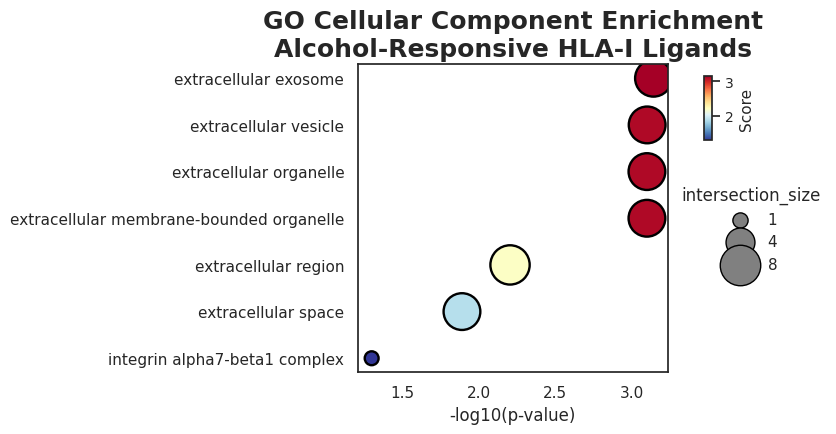

In [23]:
import matplotlib.colors as mcolors

plot_df = (
    go_bp
    .sort_values("p_value")
    .head(15)
    .copy()
)

plot_df["Score"] = -np.log10(
    plot_df["p_value"]
)


fig, ax = plt.subplots(
    figsize=(4,4)
)

sns.scatterplot(
    data=plot_df,
    x="Score",
    y="name",
    size="intersection_size",
    hue="Score",
    sizes=(100,800),
    palette="RdYlBu_r",
    edgecolor="black",
    ax=ax
)

# Define the norm variable here using the Score column limits
norm = mcolors.Normalize(
    vmin=plot_df["Score"].min(),
    vmax=plot_df["Score"].max()
)

sm = plt.cm.ScalarMappable(
    cmap="RdYlBu_r",
    norm=norm
)
sm.set_array([])

# [left, bottom, width, height]
cax = fig.add_axes([0.99, 0.69, 0.02, 0.16])

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("Score", fontsize=11)
cbar.ax.tick_params(labelsize=10)

sizes = [1,4,8]

handles = [
    plt.scatter(
        [],
        [],
        s=np.interp(
            s,
            [plot_df["intersection_size"].min(),
             plot_df["intersection_size"].max()],
            [120,850]
        ),
        color="gray",
        edgecolor="black"
    )
    for s in sizes
]

ax.set_xlabel(
    "-log10(p-value)"
)

ax.set_ylabel("")

ax.set_title(
    "GO Cellular Component Enrichment\nAlcohol-Responsive HLA-I Ligands",
    fontsize=18,
    fontweight="bold"
)

ax.legend(
    handles,
    [str(s) for s in sizes],
    title="intersection_size",
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1,0.65),
    fontsize=11,
    title_fontsize=12
)

fig.tight_layout(rect=[0,0,0.72,1])

plt.savefig(
    "GO_CC_Alcohol_Responsive_Ligands.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

      Sample   Shannon Condition
0   P004_CTL  2.636744       CTL
1   P114_CTL  2.885469       CTL
2   P118_CTL  4.086557       CTL
3  P004_ETOH  4.017846      ETOH
4  P114_ETOH  2.171862      ETOH
5  P118_ETOH  4.197073      ETOH


/tmp/ipykernel_5436/3828323439.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


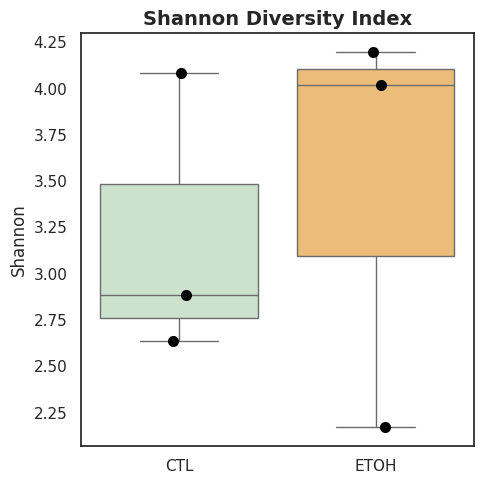

In [24]:
import pandas as pd
import numpy as np
from scipy.stats import entropy
import seaborn as sns
import matplotlib.pyplot as plt

shannon_results = []

for sample in matrix.columns:

    abund = matrix[sample]

    abund = abund[abund > 0]

    rel_abund = abund / abund.sum()

    shannon = entropy(
        rel_abund,
        base=np.e
    )

    shannon_results.append([
        sample,
        shannon,
        sample.split("_")[1]
    ])

shannon_df = pd.DataFrame(
    shannon_results,
    columns=[
        "Sample",
        "Shannon",
        "Condition"
    ]
)

print(shannon_df)

colors = {
    "CTL": "#C8E6C9",
    "ETOH": "#FFC067"
}

plt.figure(figsize=(5,5))

sns.boxplot(
    data=shannon_df,
    x="Condition",
    y="Shannon",
    palette=colors
)

sns.stripplot(
    data=shannon_df,
    x="Condition",
    y="Shannon",
    color="black",
    size=8
)

plt.xlabel("")

plt.ylabel("Shannon")

plt.title(
    "Shannon Diversity Index",
    fontsize=14,
    fontweight="bold"
)

# sns.despine()

plt.tight_layout()
plt.savefig(
    "shannon_diversity_fragpipe.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

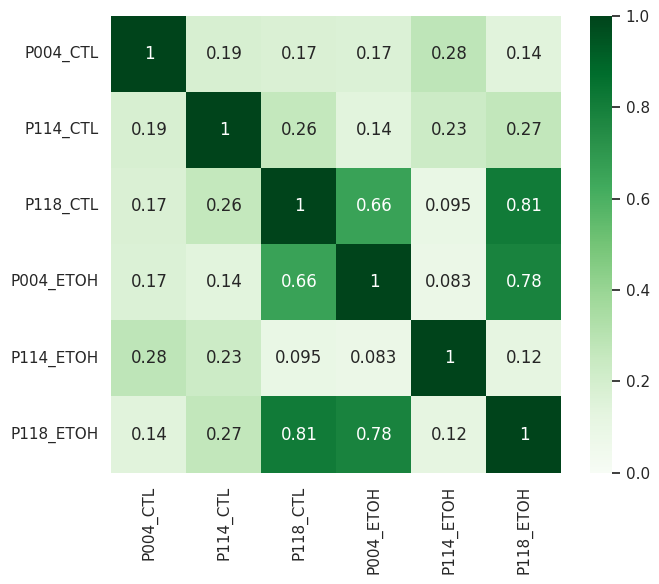

In [25]:
from sklearn.metrics import jaccard_score

presence = (
    matrix > 0
).astype(int)

samples = presence.columns

jaccard_matrix = pd.DataFrame(
    index=samples,
    columns=samples
)

for s1 in samples:

    for s2 in samples:

        score = jaccard_score(
            presence[s1],
            presence[s2]
        )

        jaccard_matrix.loc[
            s1,
            s2
        ] = score

jaccard_matrix = (
    jaccard_matrix
    .astype(float)
)

plt.figure(figsize=(7,6))

sns.heatmap(
    jaccard_matrix,
    annot=True,
    cmap="Greens",
    vmin=0,
    vmax=1
)


plt.tight_layout()
plt.savefig(
    "jaccard_similarity_fragpipe.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [26]:
pairs = [
    ("P004_CTL","P004_ETOH"),
    ("P114_CTL","P114_ETOH"),
    ("P118_CTL","P118_ETOH")
]

for ctl, etoh in pairs:

    score = jaccard_score(
        presence[ctl],
        presence[etoh]
    )

    print(
        f"{ctl} vs {etoh}: {score:.3f}"
    )

P004_CTL vs P004_ETOH: 0.167
P114_CTL vs P114_ETOH: 0.227
P118_CTL vs P118_ETOH: 0.814


      Sample  TotalIntensity Condition
0   P004_CTL      221.725226       CTL
1   P114_CTL      272.185066       CTL
2   P118_CTL     1059.711336       CTL
3  P004_ETOH      869.955427      ETOH
4  P114_ETOH      141.403492      ETOH
5  P118_ETOH     1188.619563      ETOH


/tmp/ipykernel_5436/1415148436.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


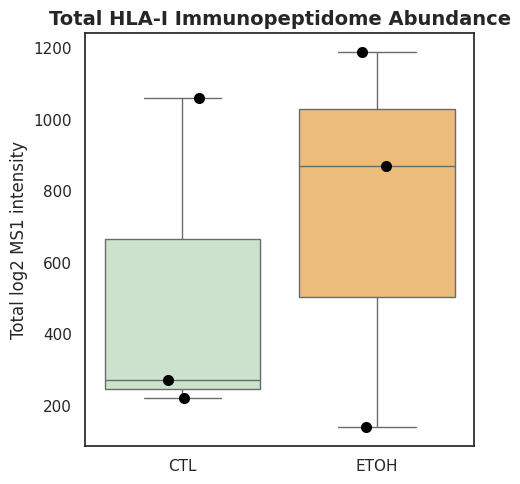

In [27]:
colors = {
    "CTL": "#2ca02c",
    "ETOH": "#ff7f0e"
}

abundance_df = pd.DataFrame({

    "Sample":
        matrix.columns,

    "TotalIntensity":
        matrix.sum(axis=0).values

})

abundance_df["Condition"] = (
    abundance_df["Sample"]
    .str.split("_")
    .str[-1]
)

print(abundance_df)


colors = {
    "CTL": "#C8E6C9",
    "ETOH": "#FFC067"
}

plt.figure(figsize=(5,5))

sns.boxplot(
    data=abundance_df,
    x="Condition",
    y="TotalIntensity",
    palette=colors
)

sns.stripplot(
    data=abundance_df,
    x="Condition",
    y="TotalIntensity",
    color="black",
    size=8
)

plt.ylabel(
    "Total log2 MS1 intensity"
)

plt.xlabel("")

plt.title(
    "Total HLA-I Immunopeptidome Abundance",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "ms1abundance_fragpipe.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
from scipy.stats import mannwhitneyu

ctl = shannon_df[
    shannon_df["Condition"]=="CTL"
]["Shannon"]

etoh = shannon_df[
    shannon_df["Condition"]=="ETOH"
]["Shannon"]

stat, p = mannwhitneyu(
    ctl,
    etoh,
    alternative="two-sided"
)

print(
    f"Shannon p-value = {p:.4f}"
)

Shannon p-value = 1.0000


In [29]:
ctl = abundance_df[
    abundance_df["Condition"]=="CTL"
]["TotalIntensity"]

etoh = abundance_df[
    abundance_df["Condition"]=="ETOH"
]["TotalIntensity"]

stat, p = mannwhitneyu(
    ctl,
    etoh
)

print(
    f"Abundance p-value = {p:.4f}"
)

Abundance p-value = 1.0000


In [30]:
COLORS = {
    "CTL": "#C8E6C9",
    "ETOH": "#FFC067",
    "SHARED": "#A0C4DF"
}

plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 16,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 18
})

FIG_DIR = "Figures"

os.makedirs(
    FIG_DIR,
    exist_ok=True
)


# Deep novo

/usr/local/lib/python3.13/dist-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/usr/local/lib/python3.13/dist-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/usr/local/lib/

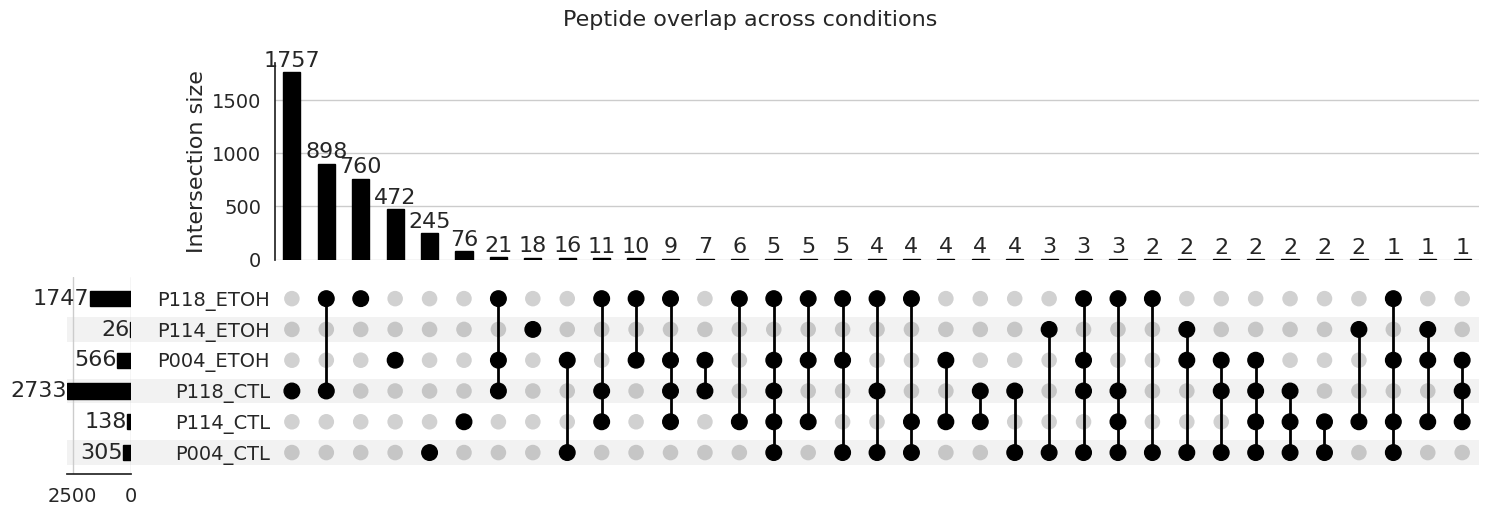

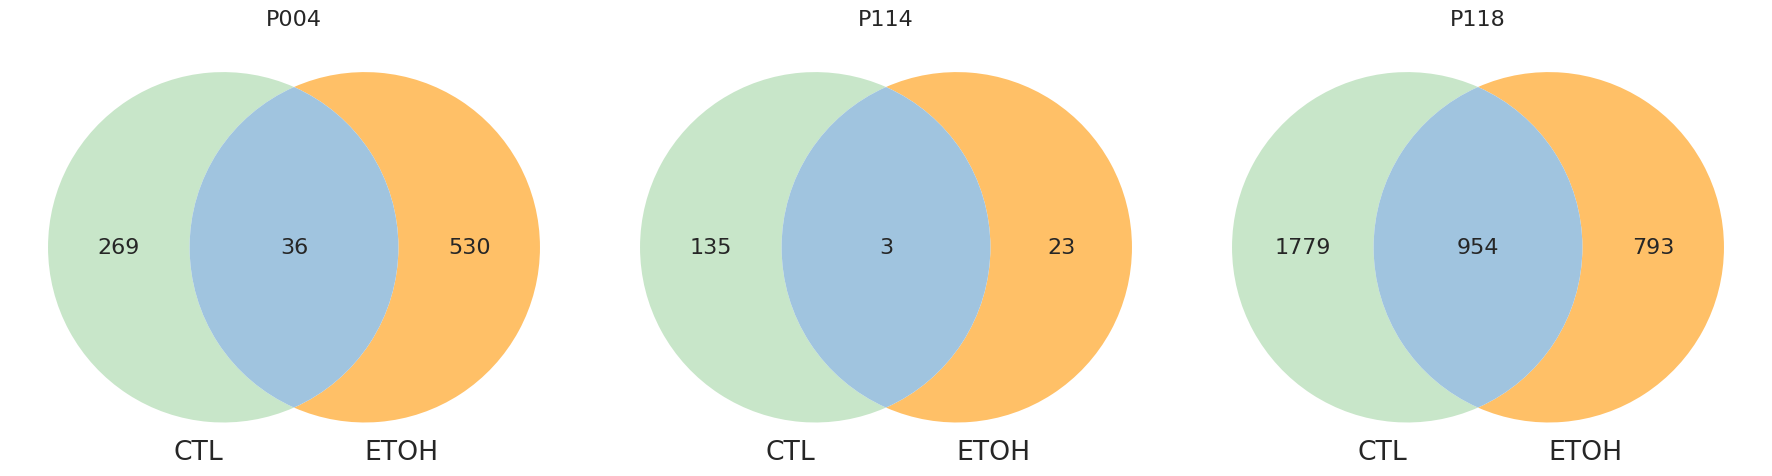

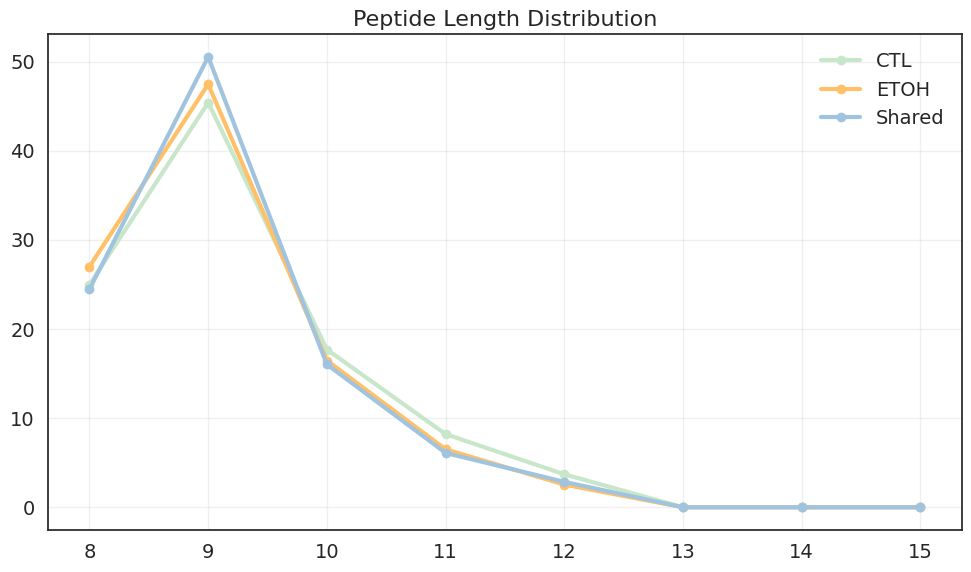

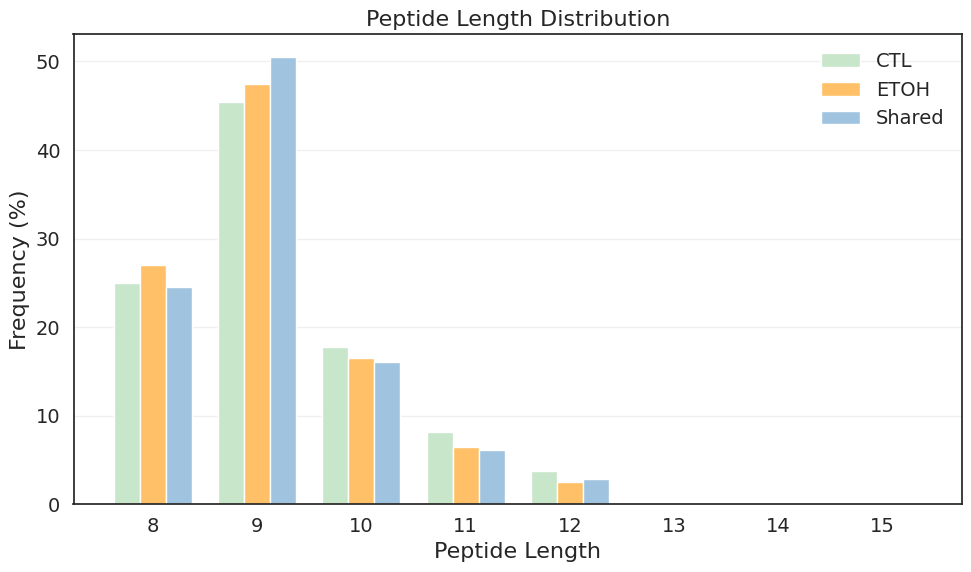


CTL_ONLY
Columns found:
['MHC', 'Peptide', 'Score_EL', '%Rank_EL', 'ndLevel']
CTL_ONLY: SB=684 | WB=472 | NON=454

ETOH_ONLY
Columns found:
['MHC', 'Peptide', 'Score_EL', '%Rank_EL', 'ndLevel']
ETOH_ONLY: SB=398 | WB=304 | NON=257

SHARED
Columns found:
['MHC', 'Peptide', 'Score_EL', '%Rank_EL', 'ndLevel']
SHARED: SB=458 | WB=306 | NON=266


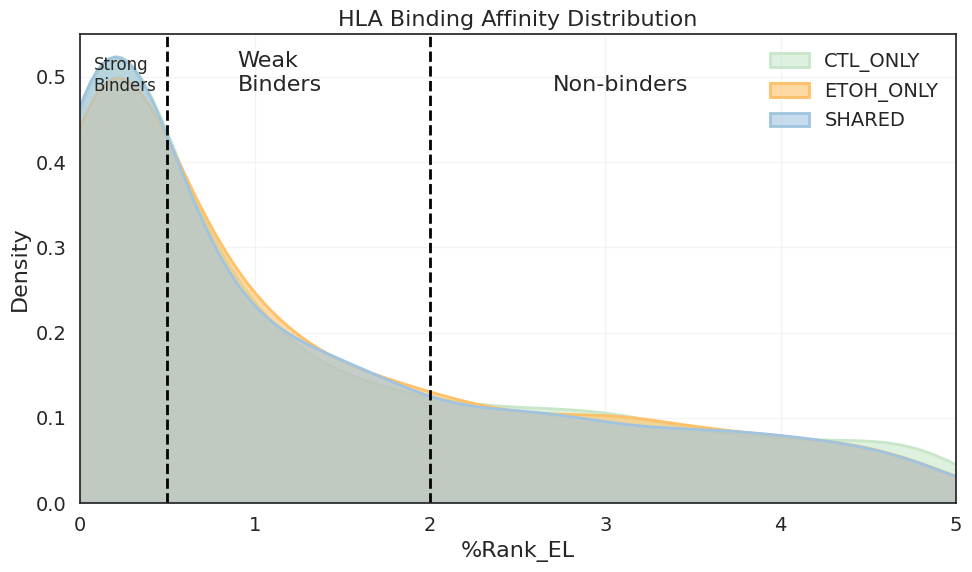

Strong binders ETOH: 398


,Peptide,%Rank_EL
241,KVYGPGVAK,0.001
1614,TTAPVVSTR,0.002
1615,TTAPVVTSR,0.002
1288,EVADPTHAR,0.002
436,STYPAVLEK,0.002
...,...,...
301,LVVSGVGTK,0.461
718,ETVGSLFSR,0.466
1410,LPAPAAVGR,0.483
1038,TSAESWQSR,0.484


In [31]:
import pandas as pd
import matplotlib.pyplot as plt
from upsetplot import from_contents, UpSet
from matplotlib_venn import venn2
import numpy as np

CTL_COLOR = "#C8E6C9"
ETOH_COLOR = "#FFC067"
SHARED_COLOR = "#A0C4DF"

file_path = "deepnovo_candidates_unfiltered.csv"
df = pd.read_csv(file_path, sep=";")

source_value_mapping = {
    "OA_12jan26_Sami-Carol_imunopep_P004_CTL.raw": "P004_CTL",
    "OA_12jan26_Sami-Carol_imunopep_P004_ETOH.raw": "P004_ETOH",
    "OA_12jan26_Sami-Carol_imunopep_P114_CTL.raw": "P114_CTL",
    "OA_12jan26_Sami-Carol_imunopep_P114_ETOH.raw": "P114_ETOH",
    "OA_12jan26_Sami-Carol_imunopep_P118_CTL.raw": "P118_CTL",
    "OA_12jan26_Sami-Carol_imunopep_P118_ETOH.raw": "P118_ETOH"
}

df["source"] = df["source"].replace(source_value_mapping)

conditions = [
    "P004_CTL","P114_CTL","P118_CTL",
    "P004_ETOH","P114_ETOH","P118_ETOH"
]

condition_sets = {}

for condition in conditions:
    condition_sets[condition] = set(
        df.loc[df["source"] == condition, "Peptide"]
        .dropna()
        .astype(str)
    )

summary = pd.DataFrame({
    "Condition": conditions,
    "N_peptides": [len(condition_sets[c]) for c in conditions]
})

summary.to_excel(
    "Deepnovo_peptide_summary.xlsx",
    index=False
)

upset_data = from_contents(condition_sets)

up = UpSet(
    upset_data,
    subset_size="count",
    show_counts=True,
    sort_by="cardinality",
    sort_categories_by=None
)

up.plot()

plt.suptitle(
    "Peptide overlap across conditions",
    fontsize=16
)

plt.savefig(
    f"{FIG_DIR}/Figure_upset_deepnovo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

patients = ["004", "114", "118"]

fig, axes = plt.subplots(1, 3, figsize=(18,6))

for i, patient in enumerate(patients):

    ctl = condition_sets[f"P{patient}_CTL"]
    etoh = condition_sets[f"P{patient}_ETOH"]

    ctl_only = len(ctl - etoh)
    etoh_only = len(etoh - ctl)
    shared = len(ctl & etoh)

    venn_diagram = venn2(
        subsets=(1,1,1),
        set_labels=("CTL","ETOH"),
        ax=axes[i]
    )

    venn_diagram.get_patch_by_id("10").set_color(CTL_COLOR)
    venn_diagram.get_patch_by_id("01").set_color(ETOH_COLOR)
    venn_diagram.get_patch_by_id("11").set_color(SHARED_COLOR)

    for region in ["10","01","11"]:
        patch = venn_diagram.get_patch_by_id(region)
        if patch is not None:
            patch.set_alpha(1.0)
            patch.set_edgecolor("none")

    venn_diagram.get_label_by_id("10").set_text(str(ctl_only))
    venn_diagram.get_label_by_id("01").set_text(str(etoh_only))
    venn_diagram.get_label_by_id("11").set_text(str(shared))

    axes[i].set_title(f"P{patient}")

plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/Figure_venn_deepnovo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

ctl_conditions = ["P004_CTL","P114_CTL","P118_CTL"]
etoh_conditions = ["P004_ETOH","P114_ETOH","P118_ETOH"]

ctl_peptides = set(
    df.loc[df["source"].isin(ctl_conditions),"Peptide"]
    .dropna().astype(str)
)

etoh_peptides = set(
    df.loc[df["source"].isin(etoh_conditions),"Peptide"]
    .dropna().astype(str)
)

shared_peptides = ctl_peptides & etoh_peptides
ctl_exclusive = ctl_peptides - etoh_peptides
etoh_exclusive = etoh_peptides - ctl_peptides

pd.DataFrame({"Peptide":sorted(shared_peptides)}).to_csv(
    "Shared_Peptides_DEEPNOVO.csv", index=False
)

pd.DataFrame({"Peptide":sorted(ctl_exclusive)}).to_csv(
    "Exclusive_CTL_Peptides_DEEPNOVO.csv", index=False
)

pd.DataFrame({"Peptide":sorted(etoh_exclusive)}).to_csv(
    "Exclusive_ETOH_Peptides_DEEPNOVO.csv", index=False
)

ctl_lengths = pd.Series(
    [len(p) for p in ctl_peptides]
)

etoh_lengths = pd.Series(
    [len(p) for p in etoh_peptides]
)

shared_lengths = pd.Series(
    [len(p) for p in shared_peptides]
)

ctl_lengths = ctl_lengths[
    ctl_lengths.between(8,15)
]

etoh_lengths = etoh_lengths[
    etoh_lengths.between(8,15)
]

shared_lengths = shared_lengths[
    shared_lengths.between(8,15)
]

ctl_freq = (
    ctl_lengths
    .value_counts()
    .sort_index()
)

etoh_freq = (
    etoh_lengths
    .value_counts()
    .sort_index()
)

shared_freq = (
    shared_lengths
    .value_counts()
    .sort_index()
)

ctl_freq = ctl_freq / ctl_freq.sum() * 100
etoh_freq = etoh_freq / etoh_freq.sum() * 100
shared_freq = shared_freq / shared_freq.sum() * 100

length_range = range(8,16)

ctl_freq = ctl_freq.reindex(
    length_range,
    fill_value=0
)

etoh_freq = etoh_freq.reindex(
    length_range,
    fill_value=0
)

shared_freq = shared_freq.reindex(
    length_range,
    fill_value=0
)

plt.figure(figsize=(10,6))

plt.plot(
    ctl_freq.index,
    ctl_freq.values,
    marker="o",
    linewidth=3,
    color=CTL_COLOR,
    label="CTL"
)

plt.plot(
    etoh_freq.index,
    etoh_freq.values,
    marker="o",
    linewidth=3,
    color=ETOH_COLOR,
    label="ETOH"
)

plt.plot(
    shared_freq.index,
    shared_freq.values,
    marker="o",
    linewidth=3,
    color=SHARED_COLOR,
    label="Shared"
)

# plt.xlabel(
#     "Peptide Length",
#     fontsize=14
# )

# plt.ylabel(
#     "Frequency (%)",
#     fontsize=14
# )

plt.title(
    "Peptide Length Distribution",
)

plt.xticks(range(8,16))

plt.legend(
    frameon=False
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{FIG_DIR}/Figure_lengthdistribution_deepnovo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

freq_df = pd.DataFrame({
    "CTL": ctl_freq,
    "ETOH": etoh_freq,
    "Shared": shared_freq
}).fillna(0)

x = np.arange(len(freq_df.index))
width = 0.25

plt.figure(figsize=(10,6))

plt.bar(
    x - width,
    freq_df["CTL"],
    width=width,
    color=CTL_COLOR,
    label="CTL"
)

plt.bar(
    x,
    freq_df["ETOH"],
    width=width,
    color=ETOH_COLOR,
    label="ETOH"
)

plt.bar(
    x + width,
    freq_df["Shared"],
    width=width,
    color=SHARED_COLOR,
    label="Shared"
)

plt.xlabel(
    "Peptide Length",
    # fontsize=14
)

plt.ylabel(
    "Frequency (%)",
    # fontsize=14
)

plt.title(
    "Peptide Length Distribution",
    # fontsize=18
)

plt.xticks(
    x,
    freq_df.index
)

plt.legend(
    frameon=False
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{FIG_DIR}/Figure_lengthdistribution_deepnovo_barplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

files = {
    "CTL_ONLY": "onlyctl_deep.txt",
    "ETOH_ONLY": "onlyetoh_deep.txt",
    "SHARED": "shared_deep.txt"
}

colors = {
    "CTL_ONLY": "#C8E6C9",
    "ETOH_ONLY": "#FFC067",
    "SHARED": "#A0C4DF"
}

plt.figure(figsize=(10,6))

for label, path in files.items():

    df = pd.read_csv(path, sep="\t")

    print(f"\n{label}")
    print("Columns found:")
    print(df.columns.tolist())

    df = (
        df[["Peptide", "%Rank_EL"]]
        .dropna()
        .rename(columns={"%Rank_EL": "Rank"})
    )

    df = df[
        df["Rank"].between(0,5)
    ]

    strong = (
        df["Rank"] <= 0.5
    ).sum()

    weak = (
        (df["Rank"] > 0.5) &
        (df["Rank"] <= 2)
    ).sum()

    non = (
        df["Rank"] > 2
    ).sum()

    print(
        f"{label}: "
        f"SB={strong} | "
        f"WB={weak} | "
        f"NON={non}"
    )

    import seaborn as sns
    sns.kdeplot(
        data=df,
        x="Rank",
        fill=True,
        common_norm=False,
        alpha=0.6,
        linewidth=2,
        label=label,
        color=colors[label]
    )

plt.axvline(
    0.5,
    linestyle="--",
    linewidth=2,
    color="black"
)

plt.axvline(
    2,
    linestyle="--",
    linewidth=2,
    color="black"
)

ymax = plt.ylim()[1]

plt.text(
    0.08,
    ymax * 0.88,
    "Strong\nBinders",
    fontsize=12
)

plt.text(
    0.9,
    ymax * 0.88,
    "Weak\nBinders",
    # fontsize=12
)

plt.text(
    2.7,
    ymax * 0.88,
    "Non-binders",
    # fontsize=12
)

plt.xlabel(
    "%Rank_EL",
    # fontsize=14
)

plt.ylabel(
    "Density",
    # fontsize=14
)

plt.title(
    "HLA Binding Affinity Distribution",
    # fontsize=18
)

plt.legend(
    frameon=False,
    # fontsize=11
)

plt.xlim(0,5)

plt.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/Figure_bindingaffinity_deepnovo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# FIXED: Read onlyetoh_deep.txt using pd.read_csv with tab separator instead of pd.read_excel
etoh_df = pd.read_csv("onlyetoh_deep.txt", sep="\t")

etoh_strong = (
    etoh_df[
        etoh_df["%Rank_EL"] <= 0.5
    ]
    .sort_values("%Rank_EL")
)

print(f"Strong binders ETOH: {len(etoh_strong)}")

display(
    etoh_strong[
        ["Peptide", "%Rank_EL"]
    ]
)

etoh_strong.to_excel(
    "ETOH_Strong_Binders_deepnovo.xlsx",
    index=False
)

CTL total: 3107
ETOH total: 2277
Shared: 1017
CTL only: 2090
ETOH only: 1260


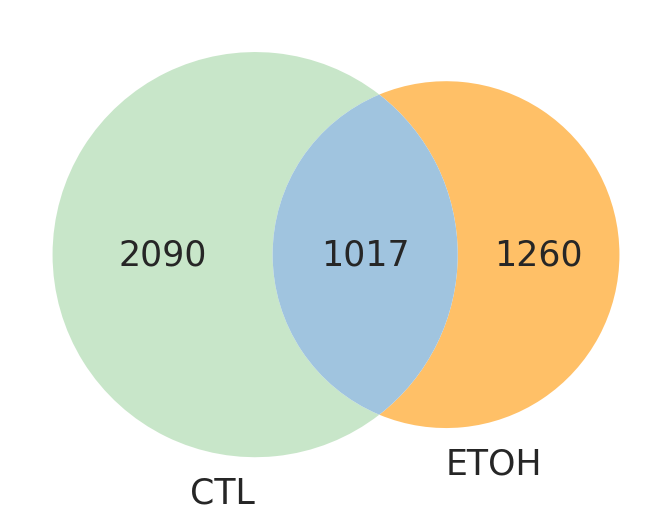

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

df = pd.read_csv(
    "deepnovo_candidates_unfiltered.csv",
    sep=";"
)

source_value_mapping = {
    "OA_12jan26_Sami-Carol_imunopep_P004_CTL.raw": "P004_CTL",
    "OA_12jan26_Sami-Carol_imunopep_P004_ETOH.raw": "P004_ETOH",
    "OA_12jan26_Sami-Carol_imunopep_P114_CTL.raw": "P114_CTL",
    "OA_12jan26_Sami-Carol_imunopep_P114_ETOH.raw": "P114_ETOH",
    "OA_12jan26_Sami-Carol_imunopep_P118_CTL.raw": "P118_CTL",
    "OA_12jan26_Sami-Carol_imunopep_P118_ETOH.raw": "P118_ETOH"
}

df["source"] = df["source"].replace(source_value_mapping)

df["Peptide"] = (
    df["Peptide"]
    .astype(str)
    .str.strip()
    .str.upper()
)

ctl_conditions = [
    "P004_CTL",
    "P114_CTL",
    "P118_CTL"
]

etoh_conditions = [
    "P004_ETOH",
    "P114_ETOH",
    "P118_ETOH"
]

ctl_peptides = set(
    df.loc[
        df["source"].isin(ctl_conditions),
        "Peptide"
    ].dropna()
)

etoh_peptides = set(
    df.loc[
        df["source"].isin(etoh_conditions),
        "Peptide"
    ].dropna()
)

ctl_only = ctl_peptides - etoh_peptides
etoh_only = etoh_peptides - ctl_peptides
shared = ctl_peptides & etoh_peptides

print(f"CTL total: {len(ctl_peptides)}")
print(f"ETOH total: {len(etoh_peptides)}")
print(f"Shared: {len(shared)}")
print(f"CTL only: {len(ctl_only)}")
print(f"ETOH only: {len(etoh_only)}")

pd.DataFrame(
    {"Peptide": sorted(shared)}
).to_excel(
    "Shared_Peptides_DEEPNOVO.xlsx",
    index=False
)

pd.DataFrame(
    {"Peptide": sorted(ctl_only)}
).to_excel(
    "CTL_Only_Peptides_DEEPNOVO.xlsx",
    index=False
)

pd.DataFrame(
    {"Peptide": sorted(etoh_only)}
).to_excel(
    "ETOH_Only_Peptides_DEEPNOVO.xlsx",
    index=False
)


plt.figure(figsize=(7,7))

venn = venn2(
    subsets=(
        len(ctl_only),
        len(etoh_only),
        len(shared)
    ),
    set_labels=("CTL", "ETOH")
)

venn.get_patch_by_id("10").set_color("#C8E6C9")
venn.get_patch_by_id("01").set_color("#FFC067")

if venn.get_patch_by_id("11") is not None:
    venn.get_patch_by_id("11").set_color("#A0C4DF")

for region in ["10", "01", "11"]:
    patch = venn.get_patch_by_id(region)
    if patch is not None:
        patch.set_alpha(1)
        patch.set_edgecolor("none")

plt.title(
    "",
    # fontsize=25
)

# Set font size for numbers in Venn diagram
for subset_id in ["10", "01", "11"]:
    subset_label = venn.get_label_by_id(subset_id)
    if subset_label is not None:
        subset_label.set_fontsize(25)

# Set font size for set labels (CTL, ETOH)
# Corrected: Use venn.set_labels instead of venn.get_texts()
for label in venn.set_labels:
    if label is not None:
        label.set_fontsize(25)

plt.tight_layout()

plt.savefig(
    f"{FIG_DIR}/Figure_venn_CTL_vs_ETOH_deepnovo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# HLA Ligand Atlas

In [93]:
#### HLA Ligand Atlas with FragPIPE dataset

In [94]:
import pandas as pd
from collections import Counter

# carregar arquivos
hla = pd.read_csv("HLA_aggregated.tsv", sep="\t")
peptides = pd.read_excel("pep_frag_hla.xlsx")

results = {}

for col in peptides.columns:

    print(f"\n{'='*60}")
    print(f"ANALISANDO: {col}")
    print(f"{'='*60}")

    peps = (
        peptides[col]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
    )

    matches = hla[
        hla["peptide_sequence"].isin(peps)
    ].copy()

    print(f"Peptídeos na coluna: {len(peps)}")
    print(f"Encontrados no Atlas: {matches['peptide_sequence'].nunique()}")

    results[col] = matches

    matches.to_excel(
        f"{col}_HLA_matches.xlsx",
        index=False
    )


ANALISANDO: CTL_SB
Peptídeos na coluna: 108
Encontrados no Atlas: 42

ANALISANDO: CTL_WB
Peptídeos na coluna: 111
Encontrados no Atlas: 37

ANALISANDO: ETOH_SB
Peptídeos na coluna: 135
Encontrados no Atlas: 90

ANALISANDO: ETOH_WB
Peptídeos na coluna: 99
Encontrados no Atlas: 62

ANALISANDO: Shared_SB
Peptídeos na coluna: 760
Encontrados no Atlas: 333

ANALISANDO: Shared_WB
Peptídeos na coluna: 589
Encontrados no Atlas: 256


In [95]:
for col, matches in results.items():

    tissue_counter = Counter()

    for tissues in matches["tissues"].dropna():

        for tissue in str(tissues).split(","):

            tissue_counter[tissue.strip()] += 1

    tissue_df = (
        pd.DataFrame(
            tissue_counter.items(),
            columns=["Tissue","Count"]
        )
        .sort_values("Count", ascending=False)
    )

    tissue_df.to_excel(
        f"{col}_Tissue_Frequency.xlsx",
        index=False
    )

    print(f"\nTop tecidos - {col}")
    print(tissue_df.head(10))


Top tecidos - CTL_SB
             Tissue  Count
4   Small intestine     20
5            Spleen     20
2              Lung     19
17           Kidney     14
6           Thyroid     13
14            Colon     12
7            Tongue     11
1       Bone marrow     11
20            Ovary     10
0           Bladder      9

Top tecidos - CTL_WB
             Tissue  Count
6              Lung     16
10           Spleen     16
9   Small intestine     15
2             Colon     11
13          Thyroid     11
8             Ovary     10
4            Kidney     10
14           Tongue     10
17          Bladder      9
3         Esophagus      9

Top tecidos - ETOH_SB
             Tissue  Count
7   Small intestine     64
4              Lung     60
8            Spleen     58
5             Ovary     54
0     Adrenal gland     53
9            Thymus     51
10           Tongue     50
19            Colon     48
21       Lymph node     47
14           Kidney     44

Top tecidos - ETOH_WB
             Tissue

In [96]:
for col, matches in results.items():

    allele_counter = Counter()

    for alleles in matches["donor_alleles"].dropna():

        for allele in str(alleles).split(","):

            allele_counter[allele.strip()] += 1

    allele_df = (
        pd.DataFrame(
            allele_counter.items(),
            columns=["Allele","Count"]
        )
        .sort_values("Count", ascending=False)
    )

    allele_df.to_excel(
        f"{col}_Allele_Frequency.xlsx",
        index=False
    )

    print(f"\nTop alelos - {col}")
    print(allele_df.head(15))


Top alelos - CTL_SB
       Allele  Count
4   n/C*03:03     35
5   n/C*04:01     35
1   n/B*15:01     34
7   s/A*68:01     30
6   n/C*07:04     25
3   n/B*44:02     25
0   n/A*32:01     23
2   n/B*35:03     22
17  s/A*11:01     16
8   w/A*11:01     13
26  n/C*06:02     12
12  n/B*35:01     12
21  n/B*13:02     11
14  n/C*03:04     11
19  n/A*24:02     11

Top alelos - CTL_WB
       Allele  Count
23  n/C*04:01     25
21  n/B*15:01     25
22  n/C*03:03     25
5   n/B*44:02     22
24  n/C*07:04     21
25  s/A*68:01     21
20  n/A*32:01     19
3   n/B*35:03     17
36  n/B*13:02     11
34  s/A*11:01     11
38  n/C*06:02     10
26  w/A*11:01      9
35  n/A*24:02      9
37  n/B*35:08      9
29  n/B*35:01      8

Top alelos - ETOH_SB
       Allele  Count
18  n/C*04:01     81
6   n/B*07:02     72
20  n/C*07:02     66
24  s/A*03:01     65
12  n/B*35:03     63
0   n/A*01:01     62
25  s/A*11:01     61
11  n/B*35:01     58
10  n/B*15:01     57
5   n/A*68:02     56
21  n/C*08:02     56
9   n/B*14:0

In [97]:
summary = []

for col in peptides.columns:

    peps = (
        peptides[col]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
    )

    matches = hla[
        hla["peptide_sequence"].isin(peps)
    ]

    summary.append([
        col,
        len(peps),
        matches["peptide_sequence"].nunique(),
        round(
            matches["peptide_sequence"].nunique()
            / len(peps) * 100,
            2
        )
    ])

summary_df = pd.DataFrame(
    summary,
    columns=[
        "Group",
        "Total_Peptides",
        "Found_in_Atlas",
        "Percent"
    ]
)

summary_df

,Group,Total_Peptides,Found_in_Atlas,Percent
0,CTL_SB,108,42,38.89
1,CTL_WB,111,37,33.33
2,ETOH_SB,135,90,66.67
3,ETOH_WB,99,62,62.63
4,Shared_SB,760,333,43.82
5,Shared_WB,589,256,43.46


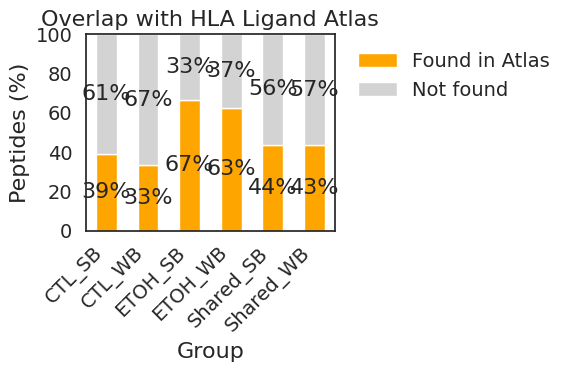

In [98]:
import pandas as pd
import matplotlib.pyplot as plt

summary = []

for col in peptides.columns:

    peps = (
        peptides[col]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
    )

    matches = hla[
        hla["peptide_sequence"].isin(peps)
    ]

    summary.append([
        col,
        len(peps),
        matches["peptide_sequence"].nunique()
    ])

summary_df = pd.DataFrame(
    summary,
    columns=["Group","Total","Atlas"]
)

summary_df["Not_found"] = (
    summary_df["Total"] -
    summary_df["Atlas"]
)

summary_df["Atlas_pct"] = (
    summary_df["Atlas"] /
    summary_df["Total"] * 100
)

summary_df["Not_found_pct"] = (
    summary_df["Not_found"] /
    summary_df["Total"] * 100
)

fig, ax = plt.subplots(figsize=(6,4))

summary_df.set_index("Group")[
    ["Atlas_pct","Not_found_pct"]
].plot(
    kind="bar",
    stacked=True,
    color=["orange","lightgray"],
    ax=ax
)

for i, row in summary_df.iterrows():

    ax.text(
        i,
        row["Atlas_pct"]/2,
        f"{row['Atlas_pct']:.0f}%",
        ha="center",
        va="center"
    )

    ax.text(
        i,
        row["Atlas_pct"] +
        row["Not_found_pct"]/2,
        f"{row['Not_found_pct']:.0f}%",
        ha="center",
        va="center"
    )

ax.set_ylim(0,100)
ax.set_ylabel("Peptides (%)")
ax.set_title("Overlap with HLA Ligand Atlas")
ax.legend(
    ["Found in Atlas", "Not found"],
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)
plt.xticks(
    rotation=45,
    ha="right"
)
plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/Figure_pepfound_frag_hla.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

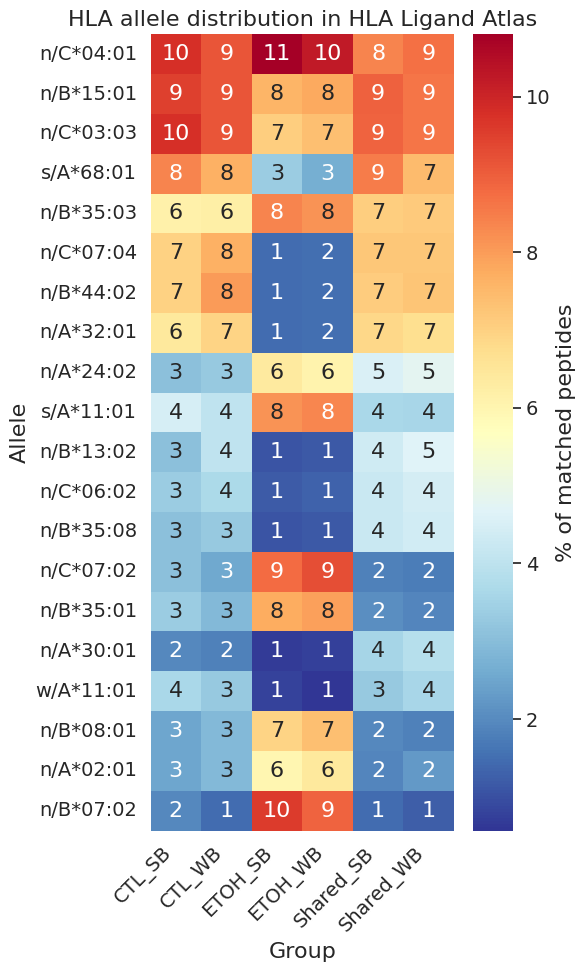

In [99]:
rows = []

for col, matches in results.items():

    for _, row in matches.iterrows():

        alleles = str(
            row["donor_alleles"]
        ).split(",")

        for allele in alleles:

            rows.append([
                col,
                allele.strip()
            ])

allele_df = pd.DataFrame(
    rows,
    columns=["Group","Allele"]
)

top_alleles = (
    allele_df["Allele"]
    .value_counts()
    .head(20)
    .index
)

allele_df = allele_df[
    allele_df["Allele"].isin(top_alleles)
]

heatmap = pd.crosstab(
    allele_df["Allele"],
    allele_df["Group"]
)

heatmap_pct = (
    heatmap
    .div(heatmap.sum(axis=0), axis=1)
    * 100
)

heatmap_pct = heatmap_pct.loc[
    heatmap.sum(axis=1)
    .sort_values(ascending=False)
    .index
]

plt.figure(figsize=(6,10))

sns.heatmap(
    heatmap_pct,
    cmap="RdYlBu_r",
    annot=True,
    fmt=".0f",
    cbar_kws={
        "label":"% of matched peptides"
    }
)

plt.title(
    "HLA allele distribution in HLA Ligand Atlas"
)


plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/Figure_alleles_fragpipe_hla.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

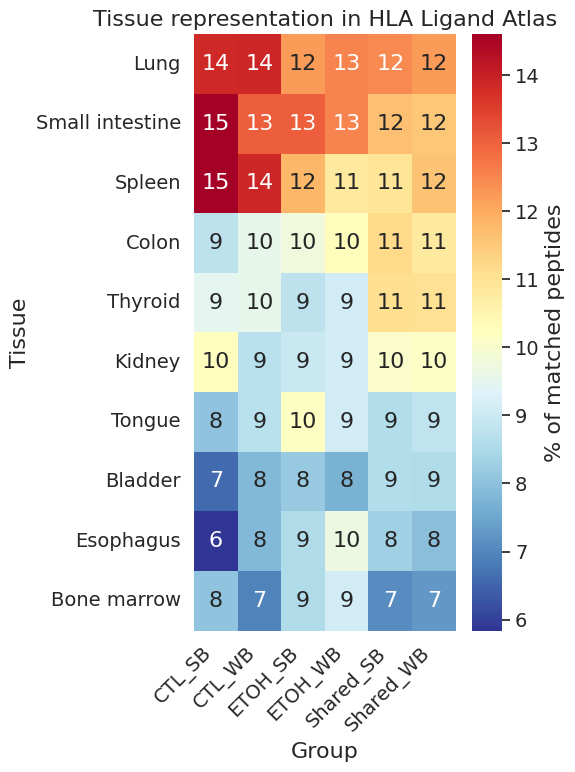

In [100]:
from collections import Counter
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

all_tissues = []

for col, matches in results.items():

    for tissues in matches["tissues"].dropna():

        for tissue in str(tissues).split(","):

            all_tissues.append(
                [col, tissue.strip()]
            )

tissue_df = pd.DataFrame(
    all_tissues,
    columns=["Group","Tissue"]
)

plot_df = (
    tissue_df.groupby(
        ["Group","Tissue"]
    )
    .size()
    .reset_index(name="Count")
)

top_tissues = (
    plot_df.groupby("Tissue")["Count"]
    .sum()
    .nlargest(10)
    .index
)

plot_df = plot_df[
    plot_df["Tissue"].isin(top_tissues)
]

pivot = plot_df.pivot(
    index="Tissue",
    columns="Group",
    values="Count"
).fillna(0)

pivot_pct = (
    pivot
    .div(pivot.sum(axis=0), axis=1)
    * 100
)

pivot_pct = pivot_pct.loc[
    pivot.sum(axis=1)
    .sort_values(ascending=False)
    .index
]

plt.figure(figsize=(6,8))

sns.heatmap(
    pivot_pct,
    cmap="RdYlBu_r",
    annot=True,
    fmt=".0f",
    cbar_kws={
        "label":"% of matched peptides"
    }
)

plt.title(
    "Tissue representation in HLA Ligand Atlas"
)

plt.tight_layout()
plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/Figure_tissue_fragpipe_hla.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [101]:
protein_map = pd.read_csv(
    "HLA_protein_map.tsv",
    sep="\t"
)

In [102]:
protein_map = pd.read_csv(
    "HLA_protein_map.tsv",
    sep="\t"
)

protein_lists = {}

for group, matches in results.items():

    proteins = (
        matches
        .merge(
            protein_map,
            on="peptide_sequence_id",
            how="left"
        )["uniprot_id"]
        .dropna()
        .unique()
    )

    protein_lists[group] = proteins

    print(
        f"{group}: {len(proteins)} proteins"
    )

    pd.DataFrame(
        {"uniprot_id": proteins}
    ).to_excel(
        f"{group}_proteins.xlsx",
        index=False
    )

CTL_SB: 60 proteins
CTL_WB: 52 proteins
ETOH_SB: 102 proteins
ETOH_WB: 70 proteins
Shared_SB: 383 proteins
Shared_WB: 293 proteins


In [103]:
ctl_all = (
    set(protein_lists["CTL_SB"]) |
    set(protein_lists["CTL_WB"])
)

etoh_all = (
    set(protein_lists["ETOH_SB"]) |
    set(protein_lists["ETOH_WB"])
)

shared_all = (
    set(protein_lists["Shared_SB"]) |
    set(protein_lists["Shared_WB"])
)

print("CTL:", len(ctl_all))
print("ETOH:", len(etoh_all))
print("Shared:", len(shared_all))

CTL: 73
ETOH: 107
Shared: 413


In [104]:
ctl_only = ctl_all - etoh_all - shared_all

etoh_only = etoh_all - ctl_all - shared_all

shared_only = shared_all - ctl_all - etoh_all

print("CTL only:", len(ctl_only))
print("ETOH only:", len(etoh_only))
print("Shared only:", len(shared_only))

CTL only: 67
ETOH only: 90
Shared only: 391


In [105]:
from gprofiler import GProfiler

gp = GProfiler(return_dataframe=True)

res_ctl = gp.profile(
    organism="hsapiens",
    query=list(ctl_only),
    sources=["GO:BP"]
)

res_etoh = gp.profile(
    organism="hsapiens",
    query=list(etoh_only),
    sources=["GO:BP"]
)

res_shared = gp.profile(
    organism="hsapiens",
    query=list(shared_only),
    sources=["GO:BP"]
)

res_ctl = res_ctl.query("p_value < 0.05")
res_etoh = res_etoh.query("p_value < 0.05")
res_shared = res_shared.query("p_value < 0.05")

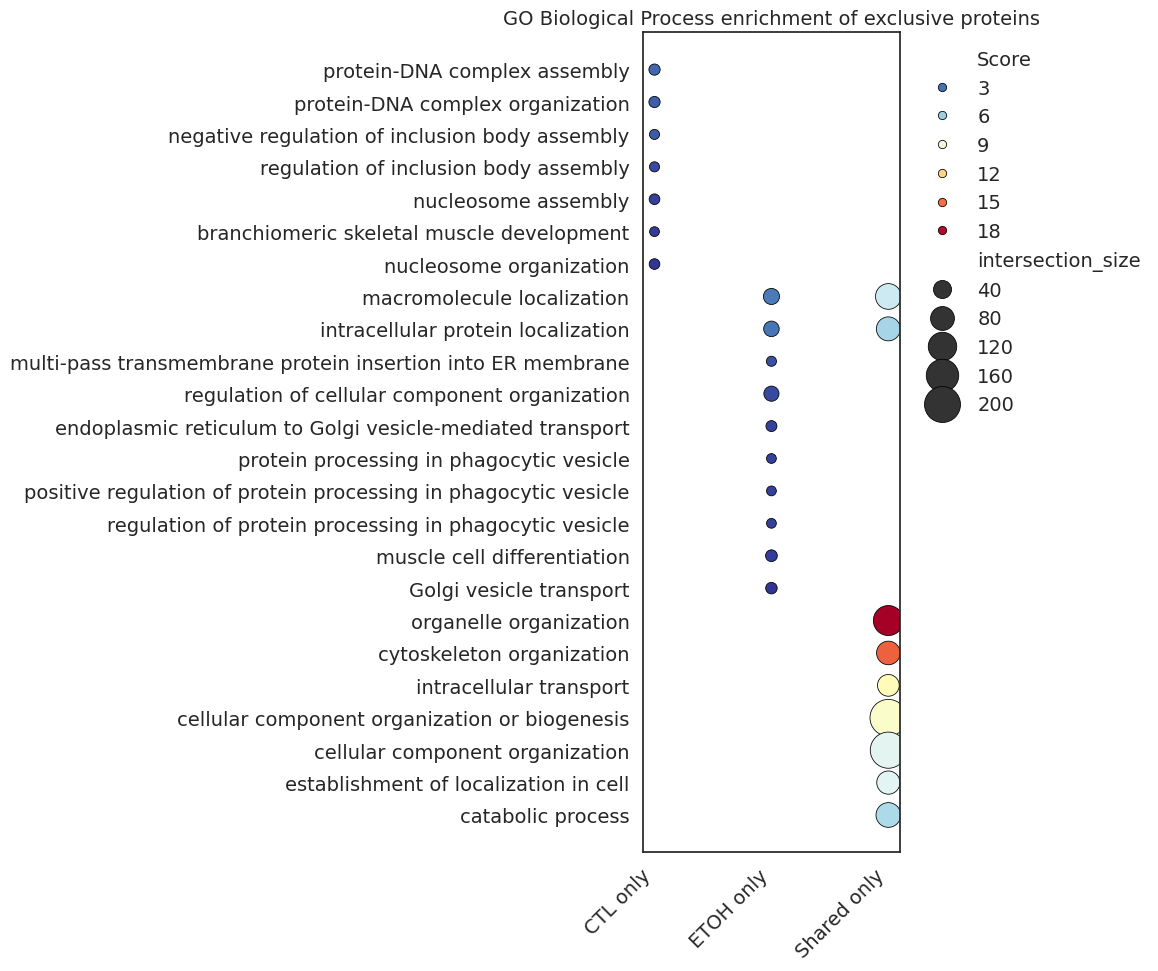

In [106]:
go_tables = {
    "CTL only": res_ctl,
    "ETOH only": res_etoh,
    "Shared only": res_shared
}

plot_list = []

for group, res in go_tables.items():

    bp = (
        res
        .sort_values("p_value")
        .head(10)
        .copy()
    )

    bp["Score"] = -np.log10(bp["p_value"])
    bp["Group"] = group

    plot_list.append(
        bp[
            [
                "name",
                "Group",
                "Score",
                "intersection_size"
            ]
        ]
    )

plot_df = pd.concat(
    plot_list,
    ignore_index=True
)

remove_terms = [
    "localization",
    "cellular localization",
    "cellular process",
    "biological process"
]

plot_df = plot_df[
    ~plot_df["name"].isin(remove_terms)
]

plt.figure(figsize=(12,10))

sns.scatterplot(
    data=plot_df,
    x="Group",
    y="name",
    size="intersection_size",
    hue="Score",
    palette="RdYlBu_r",
    sizes=(50,700),
    edgecolor="black"
)

plt.title(
    "GO Biological Process enrichment of exclusive proteins",
    fontsize=14
)

plt.xlabel("")
plt.ylabel("")

plt.legend(
    bbox_to_anchor=(1.02,1),
    loc="upper left",
    frameon=False
)
plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/Figure_GO_BP_HLA_FRAGPIPE.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [107]:
#### HLA Ligand Atlas with PEAKS dataset

In [108]:
import pandas as pd
from collections import Counter

# carregar arquivos
hla = pd.read_csv("HLA_aggregated.tsv", sep="\t")
peptides = pd.read_excel("pep_peaks_hla.xlsx")

results = {}

for col in peptides.columns:

    print(f"\n{'='*60}")
    print(f"ANALISANDO: {col}")
    print(f"{'='*60}")

    peps = (
        peptides[col]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
    )

    matches = hla[
        hla["peptide_sequence"].isin(peps)
    ].copy()

    print(f"Peptídeos na coluna: {len(peps)}")
    print(f"Encontrados no Atlas: {matches['peptide_sequence'].nunique()}")

    results[col] = matches

    matches.to_excel(
        f"{col}_HLA_matches.xlsx",
        index=False
    )


ANALISANDO: CTL_SB
Peptídeos na coluna: 454
Encontrados no Atlas: 42

ANALISANDO: CTL_WB
Peptídeos na coluna: 398
Encontrados no Atlas: 33

ANALISANDO: ETOH_SB
Peptídeos na coluna: 268
Encontrados no Atlas: 40

ANALISANDO: ETOH_WB
Peptídeos na coluna: 227
Encontrados no Atlas: 28

ANALISANDO: Shared_SB
Peptídeos na coluna: 313
Encontrados no Atlas: 58

ANALISANDO: Shared_WB
Peptídeos na coluna: 259
Encontrados no Atlas: 47


In [109]:
for col, matches in results.items():

    tissue_counter = Counter()

    for tissues in matches["tissues"].dropna():

        for tissue in str(tissues).split(","):

            tissue_counter[tissue.strip()] += 1

    tissue_df = (
        pd.DataFrame(
            tissue_counter.items(),
            columns=["Tissue","Count"]
        )
        .sort_values("Count", ascending=False)
    )

    tissue_df.to_excel(
        f"{col}_Tissue_Frequency.xlsx",
        index=False
    )

    print(f"\nTop tecidos - {col}")
    print(tissue_df.head(10))


Top tecidos - CTL_SB
             Tissue  Count
7           Thyroid     24
5   Small intestine     24
2             Colon     23
4            Kidney     21
13           Spleen     21
11             Lung     19
12         Prostate     19
3         Esophagus     16
6            Testis     16
0           Bladder     15

Top tecidos - CTL_WB
             Tissue  Count
11           Spleen     19
7           Thyroid     18
5   Small intestine     17
4            Kidney     15
2             Colon     15
12             Lung     15
6            Testis     12
14         Prostate     11
8            Tongue     10
3         Esophagus     10

Top tecidos - ETOH_SB
             Tissue  Count
8   Small intestine     27
6              Lung     27
2            Spleen     26
4     Adrenal gland     24
1             Ovary     21
10           Tongue     21
13            Colon     20
7        Lymph node     19
12           Kidney     19
3           Thyroid     19

Top tecidos - ETOH_WB
             Tissue

In [110]:
for col, matches in results.items():

    allele_counter = Counter()

    for alleles in matches["donor_alleles"].dropna():

        for allele in str(alleles).split(","):

            allele_counter[allele.strip()] += 1

    allele_df = (
        pd.DataFrame(
            allele_counter.items(),
            columns=["Allele","Count"]
        )
        .sort_values("Count", ascending=False)
    )

    allele_df.to_excel(
        f"{col}_Allele_Frequency.xlsx",
        index=False
    )

    print(f"\nTop alelos - {col}")
    print(allele_df.head(15))


Top alelos - CTL_SB
       Allele  Count
1   n/B*15:01     39
4   n/C*03:03     38
5   n/C*04:01     36
8   s/A*68:01     34
0   n/A*32:01     29
3   n/B*44:02     29
6   n/C*07:04     29
2   n/B*35:03     28
23  n/C*06:02     20
19  n/A*24:02     19
21  n/B*13:02     19
22  n/B*35:08     19
20  n/A*30:01     17
7   s/A*11:01     17
18  w/A*11:01     11

Top alelos - CTL_WB
       Allele  Count
1   n/B*15:01     26
4   n/C*03:03     26
5   n/C*04:01     25
2   n/B*35:03     20
6   n/C*07:04     20
3   n/B*44:02     20
0   n/A*32:01     19
8   s/A*68:01     19
7   s/A*11:01     14
21  n/C*06:02     12
20  n/B*35:08     12
19  n/B*13:02     12
17  n/A*24:02     11
18  n/A*30:01     10
16  n/C*07:02      8

Top alelos - ETOH_SB
       Allele  Count
8   n/C*04:01     34
4   n/B*15:01     30
19  n/B*35:03     29
9   s/A*11:01     27
2   n/B*07:02     26
29  n/C*03:03     25
13  n/A*01:01     23
26  s/A*03:01     23
5   n/B*35:01     22
16  n/A*68:02     21
22  n/C*07:02     21
23  n/C*08:0

In [111]:
summary = []

for col in peptides.columns:

    peps = (
        peptides[col]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
    )

    matches = hla[
        hla["peptide_sequence"].isin(peps)
    ]

    summary.append([
        col,
        len(peps),
        matches["peptide_sequence"].nunique(),
        round(
            matches["peptide_sequence"].nunique()
            / len(peps) * 100,
            2
        )
    ])

summary_df = pd.DataFrame(
    summary,
    columns=[
        "Group",
        "Total_Peptides",
        "Found_in_Atlas",
        "Percent"
    ]
)

summary_df

,Group,Total_Peptides,Found_in_Atlas,Percent
0,CTL_SB,454,42,9.25
1,CTL_WB,398,33,8.29
2,ETOH_SB,268,40,14.93
3,ETOH_WB,227,28,12.33
4,Shared_SB,313,58,18.53
5,Shared_WB,259,47,18.15


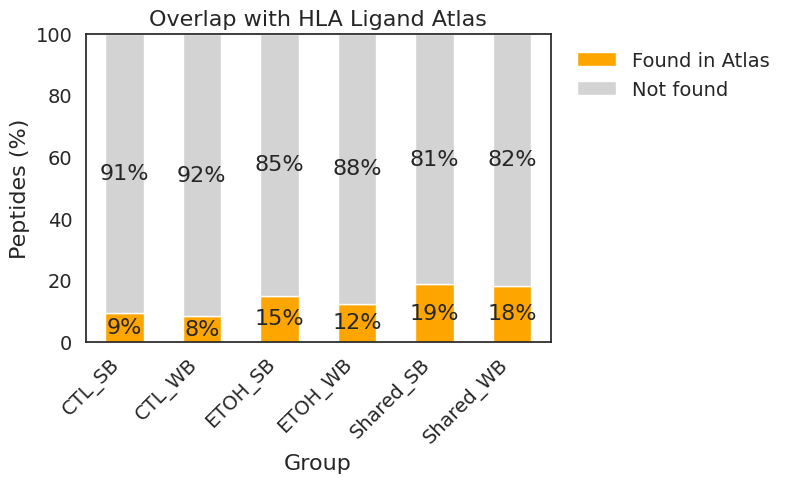

In [112]:
summary = []

for col in peptides.columns:

    peps = (
        peptides[col]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
    )

    matches = hla[
        hla["peptide_sequence"].isin(peps)
    ]

    summary.append([
        col,
        len(peps),
        matches["peptide_sequence"].nunique()
    ])

summary_df = pd.DataFrame(
    summary,
    columns=["Group","Total","Atlas"]
)

summary_df["Not_found"] = (
    summary_df["Total"] -
    summary_df["Atlas"]
)

summary_df["Atlas_pct"] = (
    summary_df["Atlas"] /
    summary_df["Total"] * 100
)

summary_df["Not_found_pct"] = (
    summary_df["Not_found"] /
    summary_df["Total"] * 100
)

fig, ax = plt.subplots(figsize=(6,4))

summary_df.set_index("Group")[
    ["Atlas_pct","Not_found_pct"]
].plot(
    kind="bar",
    stacked=True,
    color=["orange","lightgray"],
    ax=ax
)

for i, row in summary_df.iterrows():

    ax.text(
        i,
        row["Atlas_pct"]/2,
        f"{row['Atlas_pct']:.0f}%",
        ha="center",
        va="center"
    )

    ax.text(
        i,
        row["Atlas_pct"] +
        row["Not_found_pct"]/2,
        f"{row['Not_found_pct']:.0f}%",
        ha="center",
        va="center"
    )

ax.set_ylim(0,100)
ax.set_ylabel("Peptides (%)")
ax.set_title("Overlap with HLA Ligand Atlas")
ax.legend(
    ["Found in Atlas", "Not found"],
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)
plt.xticks(
    rotation=45,
    ha="right"
)

plt.savefig(
    f"{FIG_DIR}/Figure_pepfound_deep_hla.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

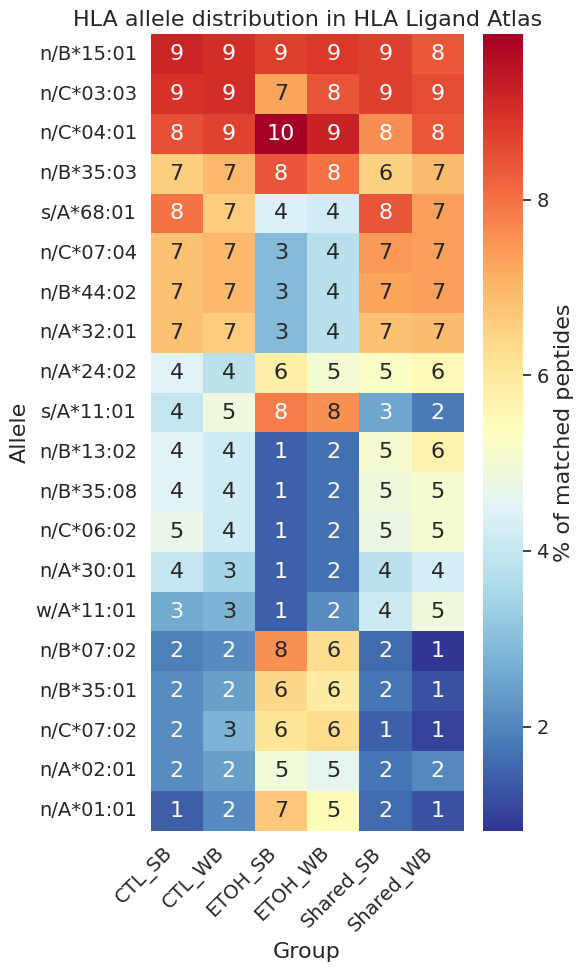

In [113]:
rows = []

for col, matches in results.items():

    for _, row in matches.iterrows():

        alleles = str(
            row["donor_alleles"]
        ).split(",")

        for allele in alleles:

            rows.append([
                col,
                allele.strip()
            ])

allele_df = pd.DataFrame(
    rows,
    columns=["Group","Allele"]
)

top_alleles = (
    allele_df["Allele"]
    .value_counts()
    .head(20)
    .index
)

allele_df = allele_df[
    allele_df["Allele"].isin(top_alleles)
]

heatmap = pd.crosstab(
    allele_df["Allele"],
    allele_df["Group"]
)

heatmap_pct = (
    heatmap
    .div(heatmap.sum(axis=0), axis=1)
    * 100
)

heatmap_pct = heatmap_pct.loc[
    heatmap.sum(axis=1)
    .sort_values(ascending=False)
    .index
]

plt.figure(figsize=(6,10))

sns.heatmap(
    heatmap_pct,
    cmap="RdYlBu_r",
    annot=True,
    fmt=".0f",
    cbar_kws={
        "label":"% of matched peptides"
    }
)

plt.title(
    "HLA allele distribution in HLA Ligand Atlas"
)


plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/Figure_alleles_deep_hla.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

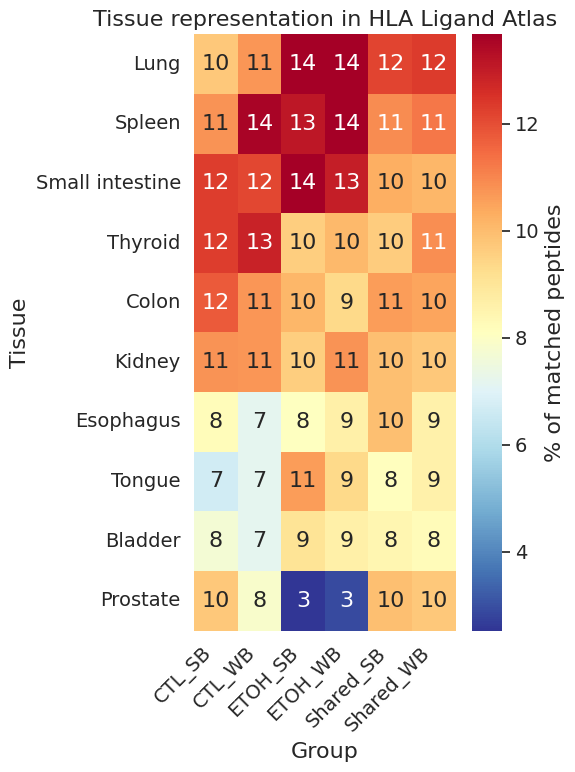

In [114]:
all_tissues = []

for col, matches in results.items():

    for tissues in matches["tissues"].dropna():

        for tissue in str(tissues).split(","):

            all_tissues.append(
                [col, tissue.strip()]
            )

tissue_df = pd.DataFrame(
    all_tissues,
    columns=["Group","Tissue"]
)

plot_df = (
    tissue_df.groupby(
        ["Group","Tissue"]
    )
    .size()
    .reset_index(name="Count")
)

top_tissues = (
    plot_df.groupby("Tissue")["Count"]
    .sum()
    .nlargest(10)
    .index
)

plot_df = plot_df[
    plot_df["Tissue"].isin(top_tissues)
]

pivot = plot_df.pivot(
    index="Tissue",
    columns="Group",
    values="Count"
).fillna(0)

pivot_pct = (
    pivot
    .div(pivot.sum(axis=0), axis=1)
    * 100
)

pivot_pct = pivot_pct.loc[
    pivot.sum(axis=1)
    .sort_values(ascending=False)
    .index
]

plt.figure(figsize=(6,8))

sns.heatmap(
    pivot_pct,
    cmap="RdYlBu_r",
    annot=True,
    fmt=".0f",
    cbar_kws={
        "label":"% of matched peptides"
    }
)

plt.title(
    "Tissue representation in HLA Ligand Atlas"
)

plt.tight_layout()
plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/Figure_tissue_deep_hla.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [115]:
protein_map = pd.read_csv(
    "HLA_protein_map.tsv",
    sep="\t"
)

In [116]:
protein_map = pd.read_csv(
    "HLA_protein_map.tsv",
    sep="\t"
)

protein_lists = {}

for group, matches in results.items():

    proteins = (
        matches
        .merge(
            protein_map,
            on="peptide_sequence_id",
            how="left"
        )["uniprot_id"]
        .dropna()
        .unique()
    )

    protein_lists[group] = proteins

    print(
        f"{group}: {len(proteins)} proteins"
    )

    pd.DataFrame(
        {"uniprot_id": proteins}
    ).to_excel(
        f"{group}_proteins.xlsx",
        index=False
    )

CTL_SB: 63 proteins
CTL_WB: 45 proteins
ETOH_SB: 43 proteins
ETOH_WB: 28 proteins
Shared_SB: 67 proteins
Shared_WB: 58 proteins


In [117]:
ctl_all = (
    set(protein_lists["CTL_SB"]) |
    set(protein_lists["CTL_WB"])
)

etoh_all = (
    set(protein_lists["ETOH_SB"]) |
    set(protein_lists["ETOH_WB"])
)

shared_all = (
    set(protein_lists["Shared_SB"]) |
    set(protein_lists["Shared_WB"])
)

print("CTL:", len(ctl_all))
print("ETOH:", len(etoh_all))
print("Shared:", len(shared_all))

CTL: 75
ETOH: 45
Shared: 76


In [118]:
ctl_only = ctl_all - etoh_all - shared_all

etoh_only = etoh_all - ctl_all - shared_all

shared_only = shared_all - ctl_all - etoh_all

print("CTL only:", len(ctl_only))
print("ETOH only:", len(etoh_only))
print("Shared only:", len(shared_only))

CTL only: 72
ETOH only: 42
Shared only: 71


In [119]:
gp = GProfiler(return_dataframe=True)

res_ctl = gp.profile(
    organism="hsapiens",
    query=list(ctl_only),
    sources=["GO:BP"]
)

res_etoh = gp.profile(
    organism="hsapiens",
    query=list(etoh_only),
    sources=["GO:BP"]
)

res_shared = gp.profile(
    organism="hsapiens",
    query=list(shared_only),
    sources=["GO:BP"]
)

res_ctl = res_ctl.query("p_value < 0.05")
res_etoh = res_etoh.query("p_value < 0.05")
res_shared = res_shared.query("p_value < 0.05")

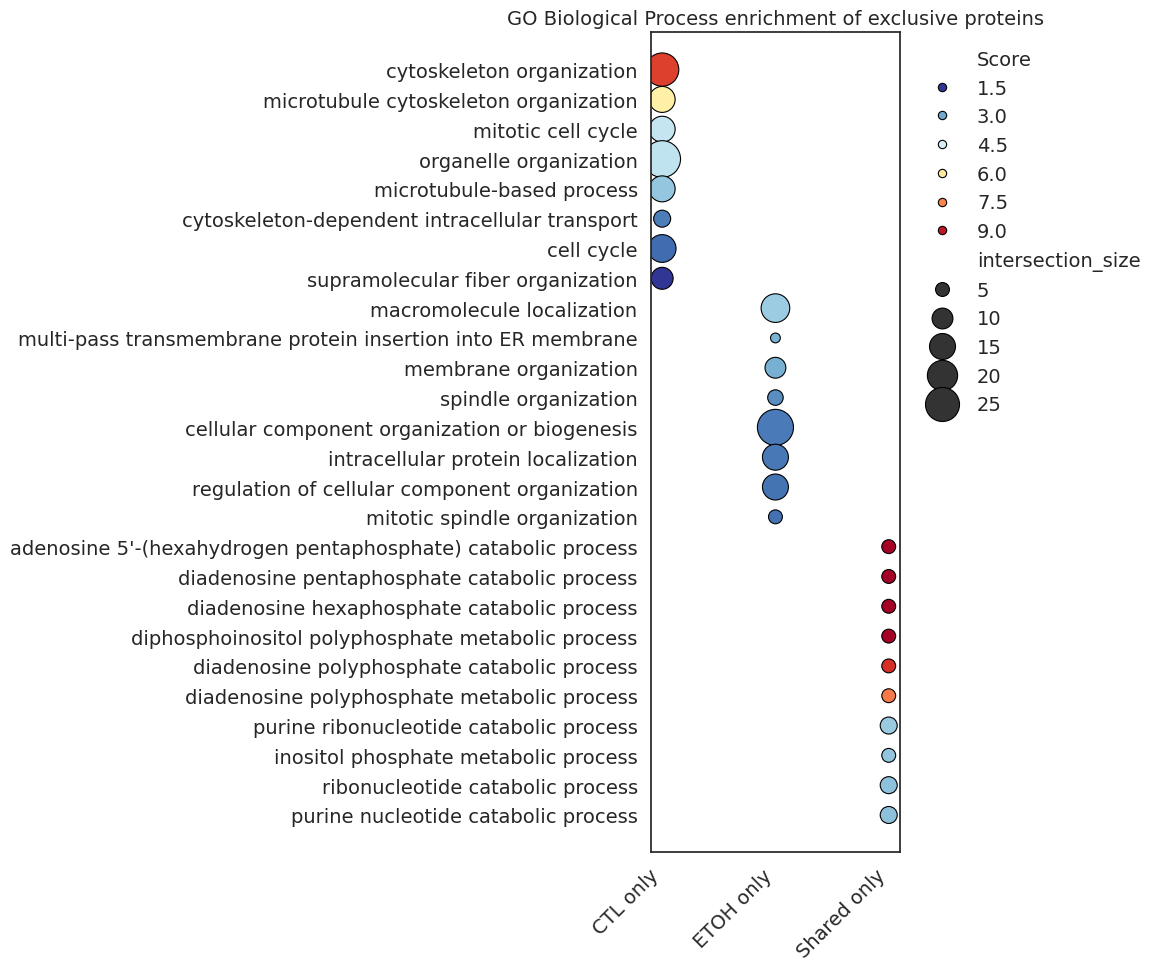

In [120]:
go_tables = {
    "CTL only": res_ctl,
    "ETOH only": res_etoh,
    "Shared only": res_shared
}

plot_list = []

for group, res in go_tables.items():

    bp = (
        res
        .sort_values("p_value")
        .head(10)
        .copy()
    )

    bp["Score"] = -np.log10(bp["p_value"])
    bp["Group"] = group

    plot_list.append(
        bp[
            [
                "name",
                "Group",
                "Score",
                "intersection_size"
            ]
        ]
    )

plot_df = pd.concat(
    plot_list,
    ignore_index=True
)
remove_terms = [
    "localization",
    "cellular localization",
    "cellular process",
    "biological process"
]

plot_df = plot_df[
    ~plot_df["name"].isin(remove_terms)
]

plt.figure(figsize=(12,10))

sns.scatterplot(
    data=plot_df,
    x="Group",
    y="name",
    size="intersection_size",
    hue="Score",
    palette="RdYlBu_r",
    sizes=(50,700),
    edgecolor="black"
)

plt.title(
    "GO Biological Process enrichment of exclusive proteins",
    fontsize=14
)

plt.xlabel("")
plt.ylabel("")

plt.legend(
    bbox_to_anchor=(1.02,1),
    loc="upper left",
    frameon=False
)
plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()
plt.savefig(
    f"{FIG_DIR}/Figure_GO_BP_HLA_PEAKS.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [121]:
#### Venn all datasets (FragPIPE and Peaks) and HLA Ligand Atlas

FragPipe peptides detected (>0): 5218
FragPipe: 5218
DeepNovo: 4367
Atlas: 223246
Only FragPipe: 2986
Only DeepNovo: 3332
Only Atlas: 221570
FragPipe + DeepNovo: 581
FragPipe + Atlas: 1222
DeepNovo + Atlas: 25
All three: 429


/usr/local/lib/python3.13/dist-packages/matplotlib_venn/_util.py:62: UserWarning: venn3_unweighted is deprecated. Use venn3 with the appropriate layout_algorithm instead.
  warnings.warn(


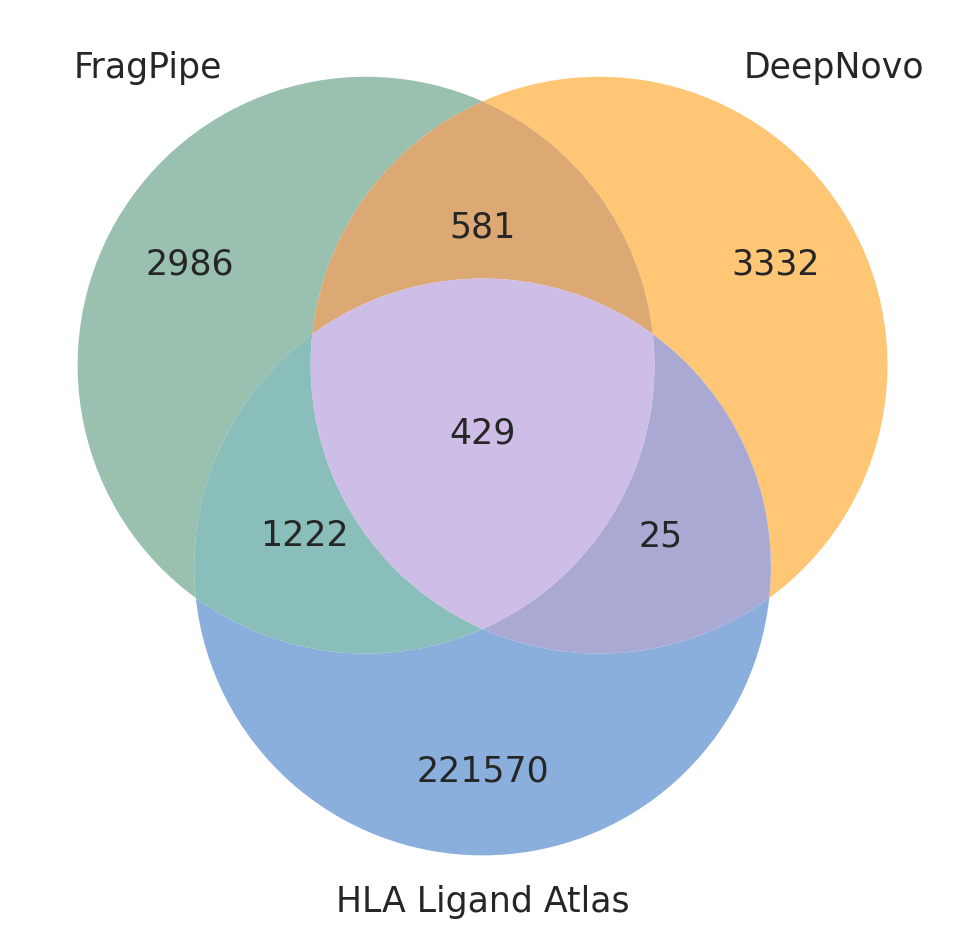

In [122]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn3_unweighted

# Fix: Load the renamed FragPipe dataset into fragpipe_df
fragpipe_df = pd.read_csv("FragPIPE_renamed.csv")

all_intensity_cols = [
    "P004_CTL", "P004_ETOH",
    "P114_CTL", "P114_ETOH",
    "P118_CTL", "P118_ETOH"
]

fragpipe_df[all_intensity_cols] = (
    fragpipe_df[all_intensity_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

fragpipe_peptides = set(
    fragpipe_df.loc[
        (fragpipe_df[all_intensity_cols] > 0).any(axis=1),
        "Peptide Sequence"
    ]
    .dropna()
    .astype(str)
    .str.strip()
    .str.upper()
)

print(
    "FragPipe peptides detected (>0):",
    len(fragpipe_peptides)
)

deepnovo_df = pd.read_csv(
    "deepnovo_candidates_unfiltered.csv",
    sep=";"
)

deepnovo_peptides = set(
    deepnovo_df["Peptide"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.upper()
)

atlas_df = pd.read_csv(
    "HLA_aggregated.tsv",
    sep="\t"
)

atlas_peptides = set(
    atlas_df["peptide_sequence"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.upper()
)

all_three = (
    fragpipe_peptides
    & deepnovo_peptides
    & atlas_peptides
)

fragpipe_deepnovo = (
    fragpipe_peptides
    & deepnovo_peptides
) - all_three

fragpipe_atlas = (
    fragpipe_peptides
    & atlas_peptides
) - all_three

deepnovo_atlas = (
    deepnovo_peptides
    & atlas_peptides
) - all_three

only_fragpipe = (
    fragpipe_peptides
    - deepnovo_peptides
    - atlas_peptides
)

only_deepnovo = (
    deepnovo_peptides
    - fragpipe_peptides
    - atlas_peptides
)

only_atlas = (
    atlas_peptides
    - fragpipe_peptides
    - deepnovo_peptides
)


print("FragPipe:", len(fragpipe_peptides))
print("DeepNovo:", len(deepnovo_peptides))
print("Atlas:", len(atlas_peptides))

print("Only FragPipe:", len(only_fragpipe))
print("Only DeepNovo:", len(only_deepnovo))
print("Only Atlas:", len(only_atlas))

print("FragPipe + DeepNovo:", len(fragpipe_deepnovo))
print("FragPipe + Atlas:", len(fragpipe_atlas))
print("DeepNovo + Atlas:", len(deepnovo_atlas))

print("All three:", len(all_three))


pd.DataFrame(
    {"Peptide": sorted(all_three)}
).to_excel(
    "Shared_FragPipe_DeepNovo_Atlas.xlsx",
    index=False
)


plt.figure(figsize=(10,10))

venn = venn3_unweighted(
    subsets=(
        len(only_fragpipe),      # 100
        len(only_deepnovo),      # 010
        len(fragpipe_deepnovo),  # 110
        len(only_atlas),         # 001
        len(fragpipe_atlas),     # 101
        len(deepnovo_atlas),     # 011
        len(all_three)           # 111
    ),
    set_labels=(
        "FragPipe",
        "DeepNovo",
        "HLA Ligand Atlas"
    )
)

region_colors = {
    "100": "#8FB9A8",  # FragPipe
    "010": "#FFC067",  # DeepNovo
    "001": "#7DA7D9",  # Atlas
    "110": "#D9A066",
    "101": "#7CB7B3",
    "011": "#A0A0D0",
    "111": "#C9B6E4"
}

for region, color in region_colors.items():

    patch = venn.get_patch_by_id(region)

    if patch is not None:
        patch.set_color(color)
        patch.set_alpha(0.9)
        patch.set_edgecolor("none")


for region in [
    "100",
    "010",
    "110",
    "001",
    "101",
    "011",
    "111"
]:
    label = venn.get_label_by_id(region)

    if label is not None:
        label.set_fontsize(25)

for label in venn.set_labels:

    if label is not None:
        label.set_fontsize(25)

plt.tight_layout()

plt.savefig(
    f"{FIG_DIR}/Venn_FragPipe_DeepNovo_HLAAtlas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()